In [1]:
import sys
from pathlib import Path

root_path = Path.cwd().parent
if str(root_path) not in sys.path:
    sys.path.append(str(root_path))

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="ticks", palette="Set2")
import pandas as pd
import glob
import os
import numpy as np
from simulation_neurog import CellSimulation
import math

layers_gaus_coef = pd.read_csv(Path.cwd().parent / 'supplementary' / 'layers_gaus_coef.csv')
layers_density = pd.read_csv(Path.cwd().parent / 'supplementary' / 'layers_percent.csv')

# sim colors
neuro_colors = ['#1c9d40', '#c21745', '#23a3ae', '#e46b0f', '#666666', "#ff7499"]
neuro_labels = ['apical P', 'basal P', 'apical N', 'basal N']
neuro_colors_dict = dict(zip(neuro_labels, neuro_colors))

# layer colors
layer_colors = {'l6': '#a400fe',
                'l5': '#e33e00',
                'l4': '#ffc000',
                'l23': '#0088ab'}
layers = layer_colors.keys()
colors = [layer_colors.get(layer, '#333333') for layer in layers]

simulation_resolution = 60

def create_sigmoid(k, x0, start, end):
    return lambda x: 1/(1 + np.exp(-k*(x - x0)))*(end - start) + start

In [2]:
CCL_sig_fc = create_sigmoid(1.0996471464169197, 2.5183915615860824, 7.735565519182058, 19.230104909327427)
CCL_lin_fc = lambda x: 2.2028571428571415 * x + 7.942857142857142
CCL_min_fc = lambda x: 7.735565519182058
CCL_avg_fc = lambda x: 13.482835214254742
CCL_max_fc = lambda x: 19.230104909327427

# Raw

In [3]:
def calc_sim_raw(b_ccl_fc = CCL_lin_fc):
    k = 0.866

    sim_raw = CellSimulation(
                n_aP0=k, n_bP0=1-k,
                b_cycle_length=b_ccl_fc,

                min_per_frame=simulation_resolution,

                layers_dist=layers_gaus_coef,
                layers_perc=layers_density,
                clip_prob=True)

    sim_raw.run()

    sim_raw.plot()

    sim_raw.plot_layers()

    return sim_raw

## raw - linear

apical setup:   0%|          | 0/192 [00:00<?, ?it/s]

calculation: 100%|██████████| 192/192 [00:20<00:00,  9.44it/s]


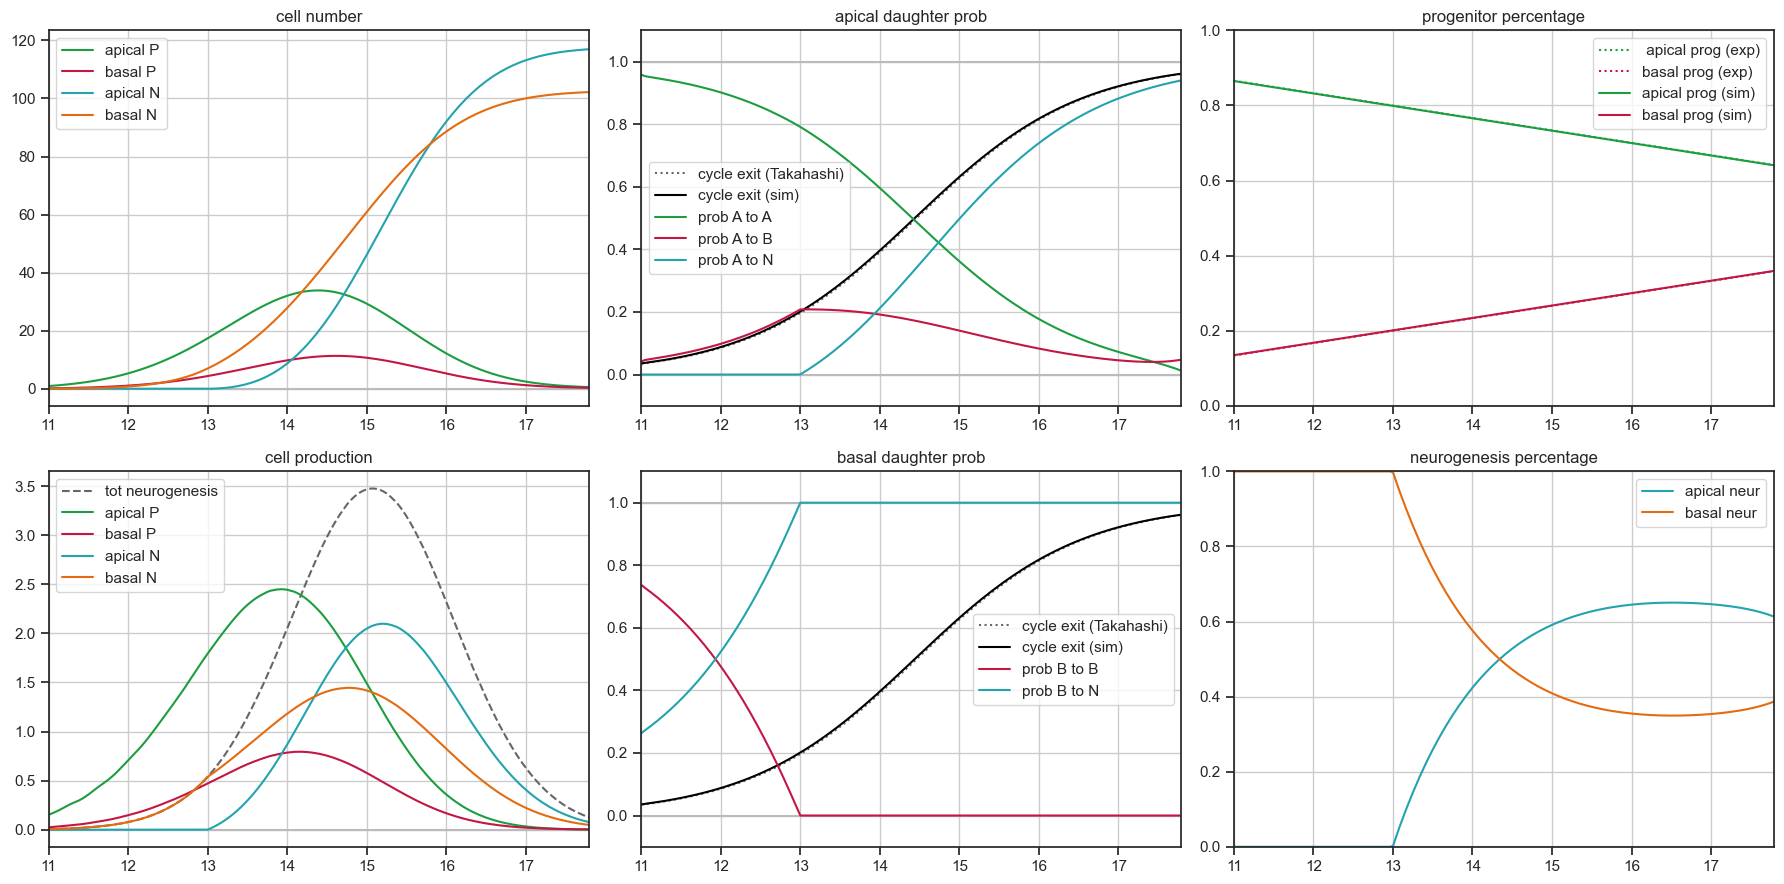

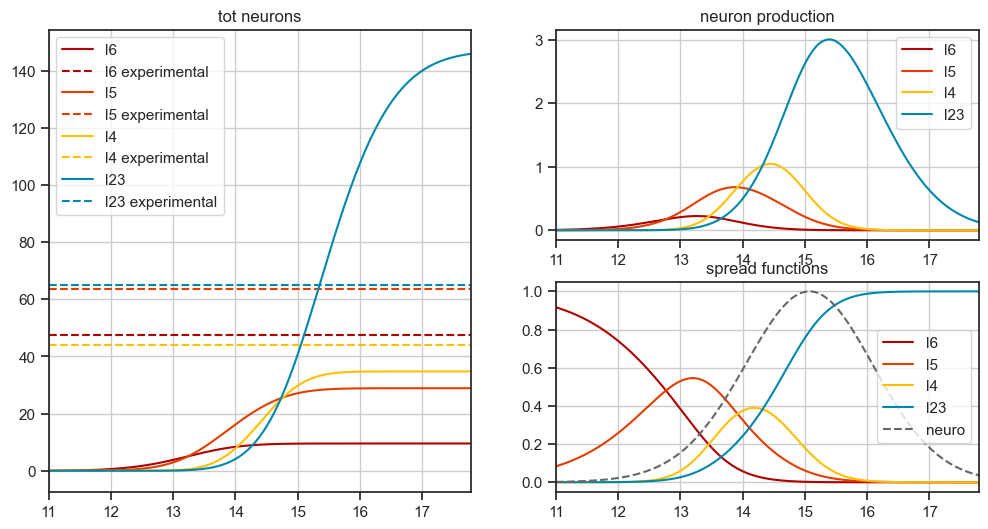

In [4]:
sim_raw = calc_sim_raw()

## raw - min

calculation: 100%|██████████| 192/192 [00:22<00:00,  8.66it/s]


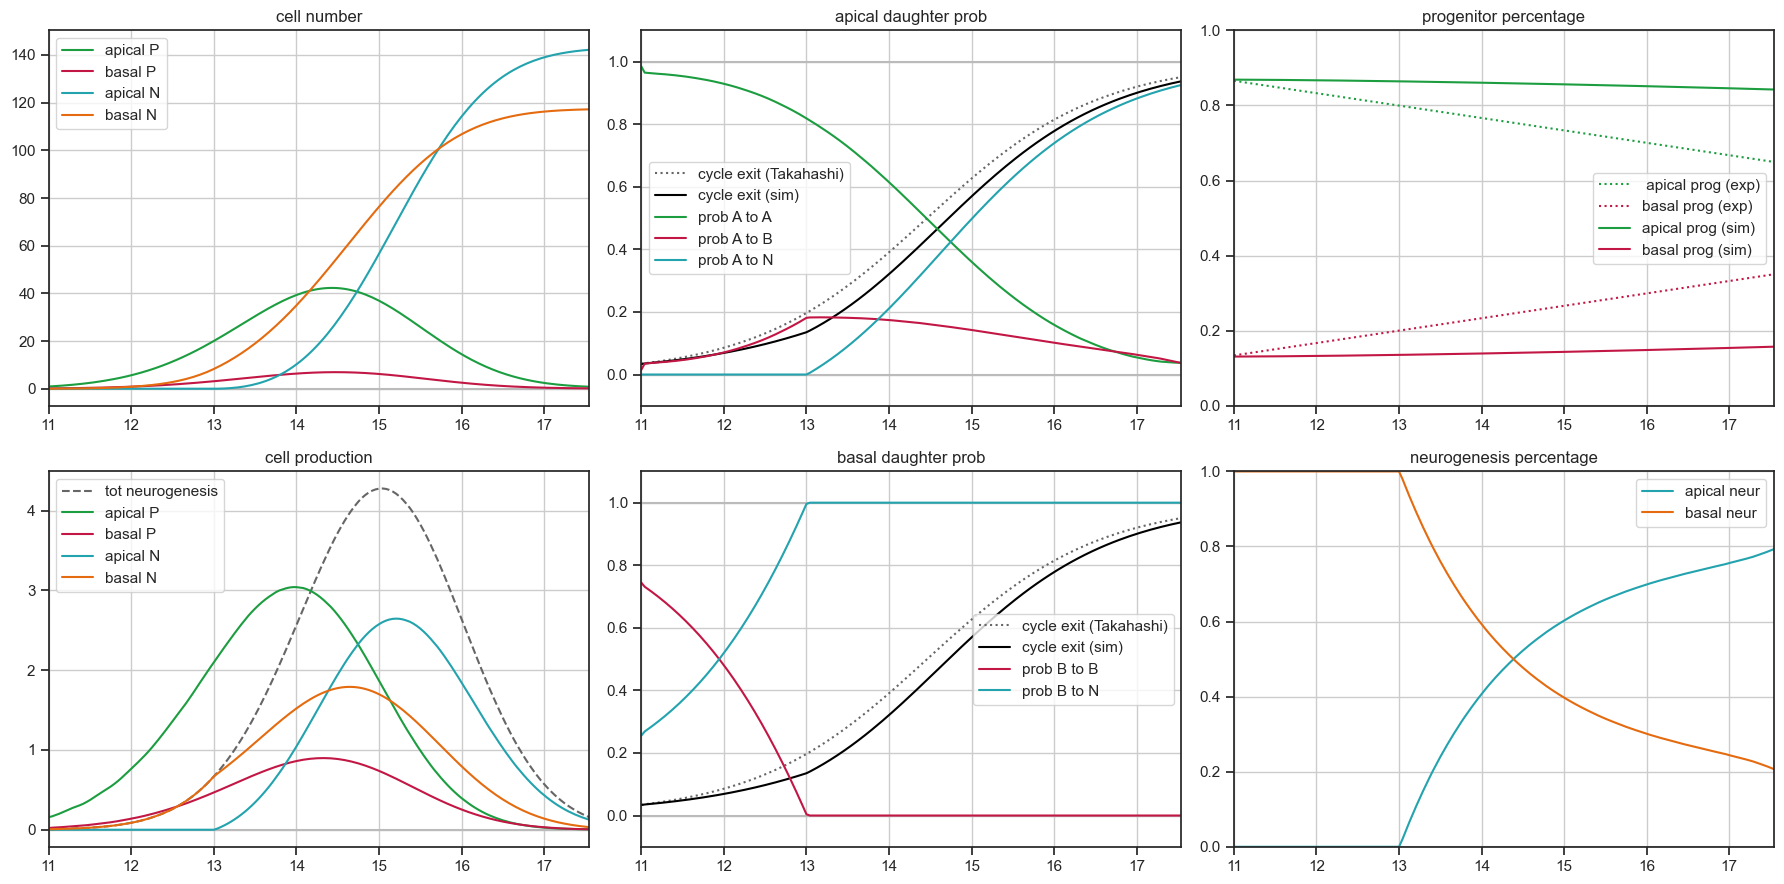

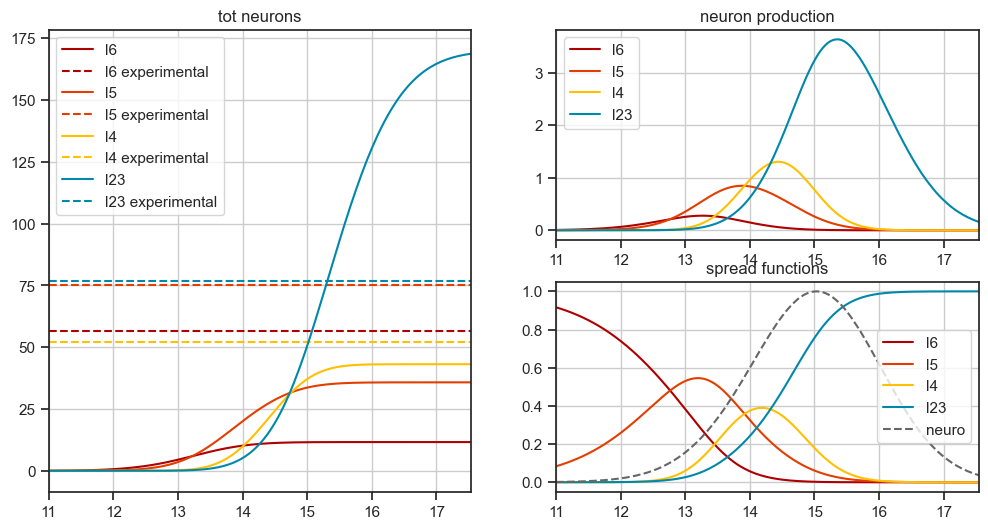

In [5]:
sim_raw_min = calc_sim_raw(CCL_min_fc)

## raw - avg

calculation: 100%|██████████| 192/192 [00:22<00:00,  8.49it/s]


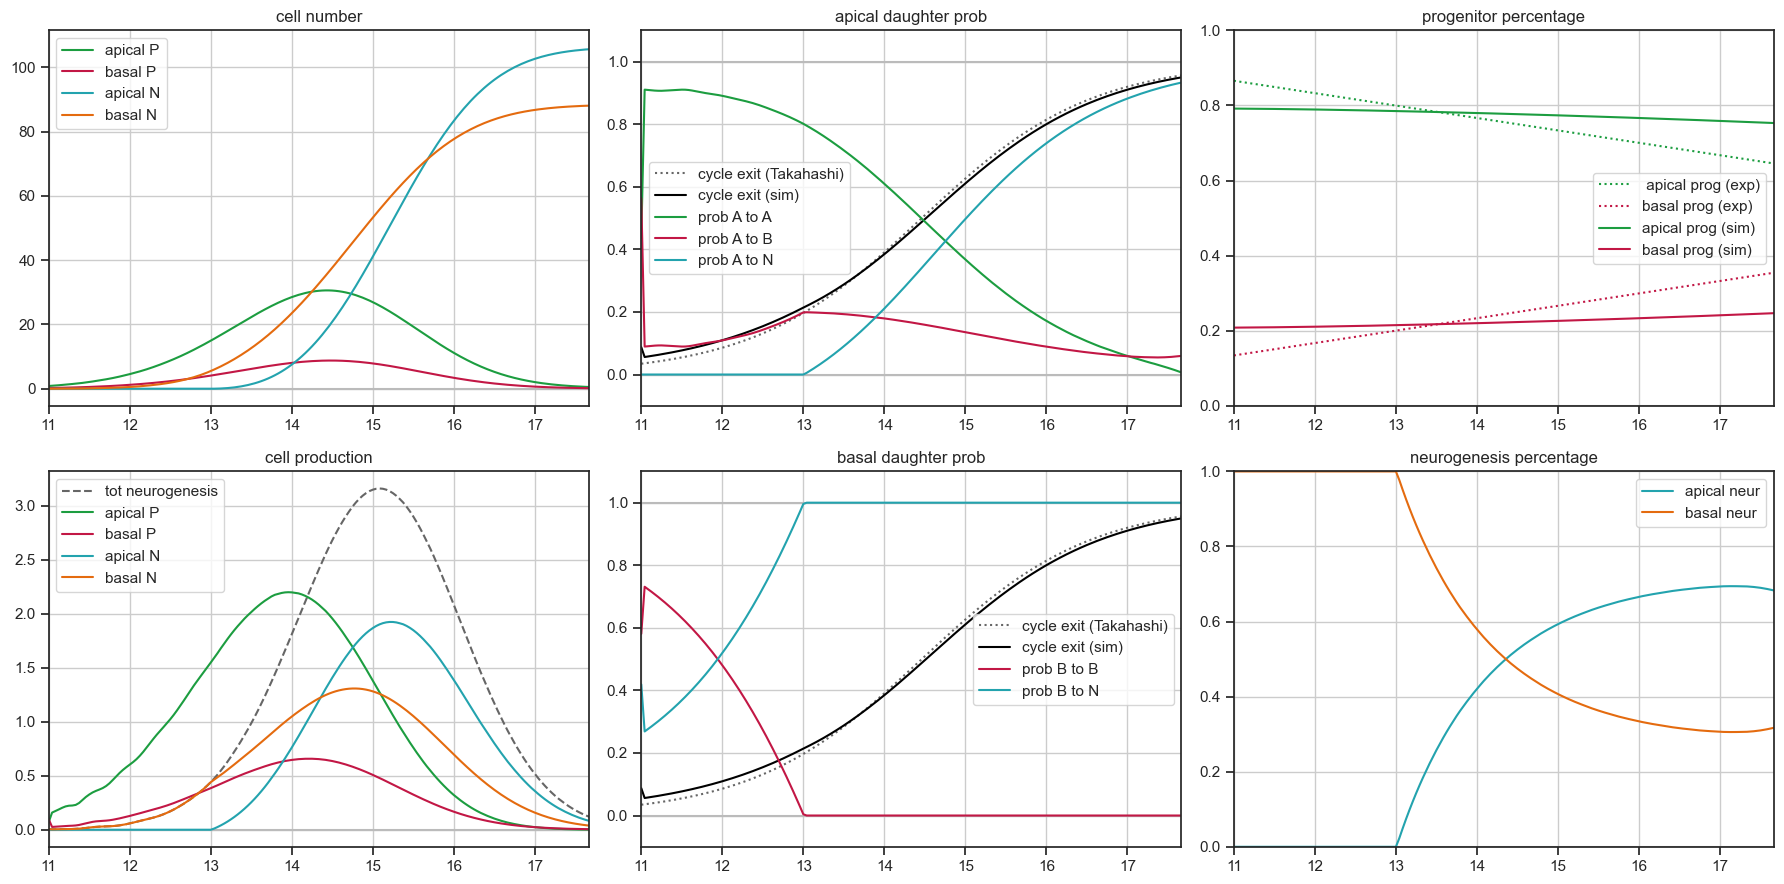

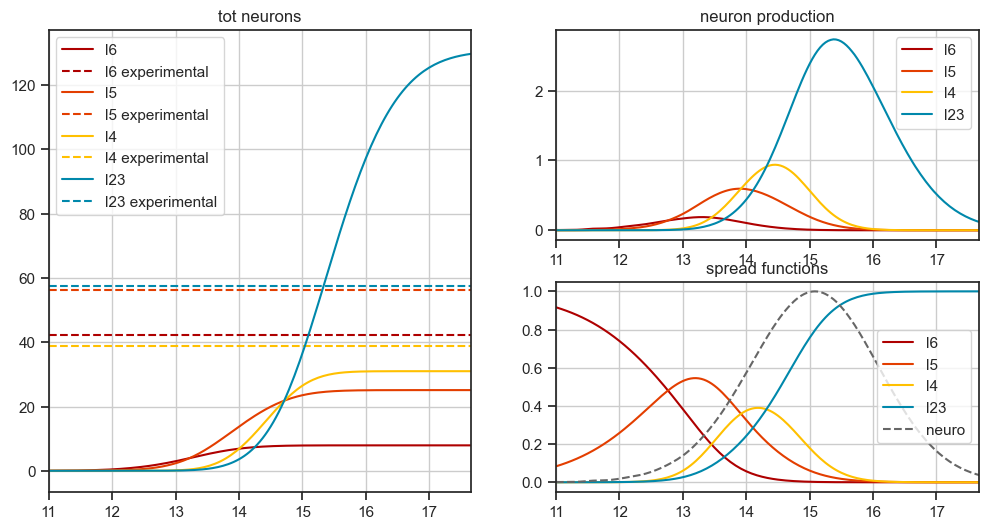

In [6]:
sim_raw_avg = calc_sim_raw(CCL_avg_fc)

## raw - max

calculation: 100%|██████████| 192/192 [00:22<00:00,  8.67it/s]


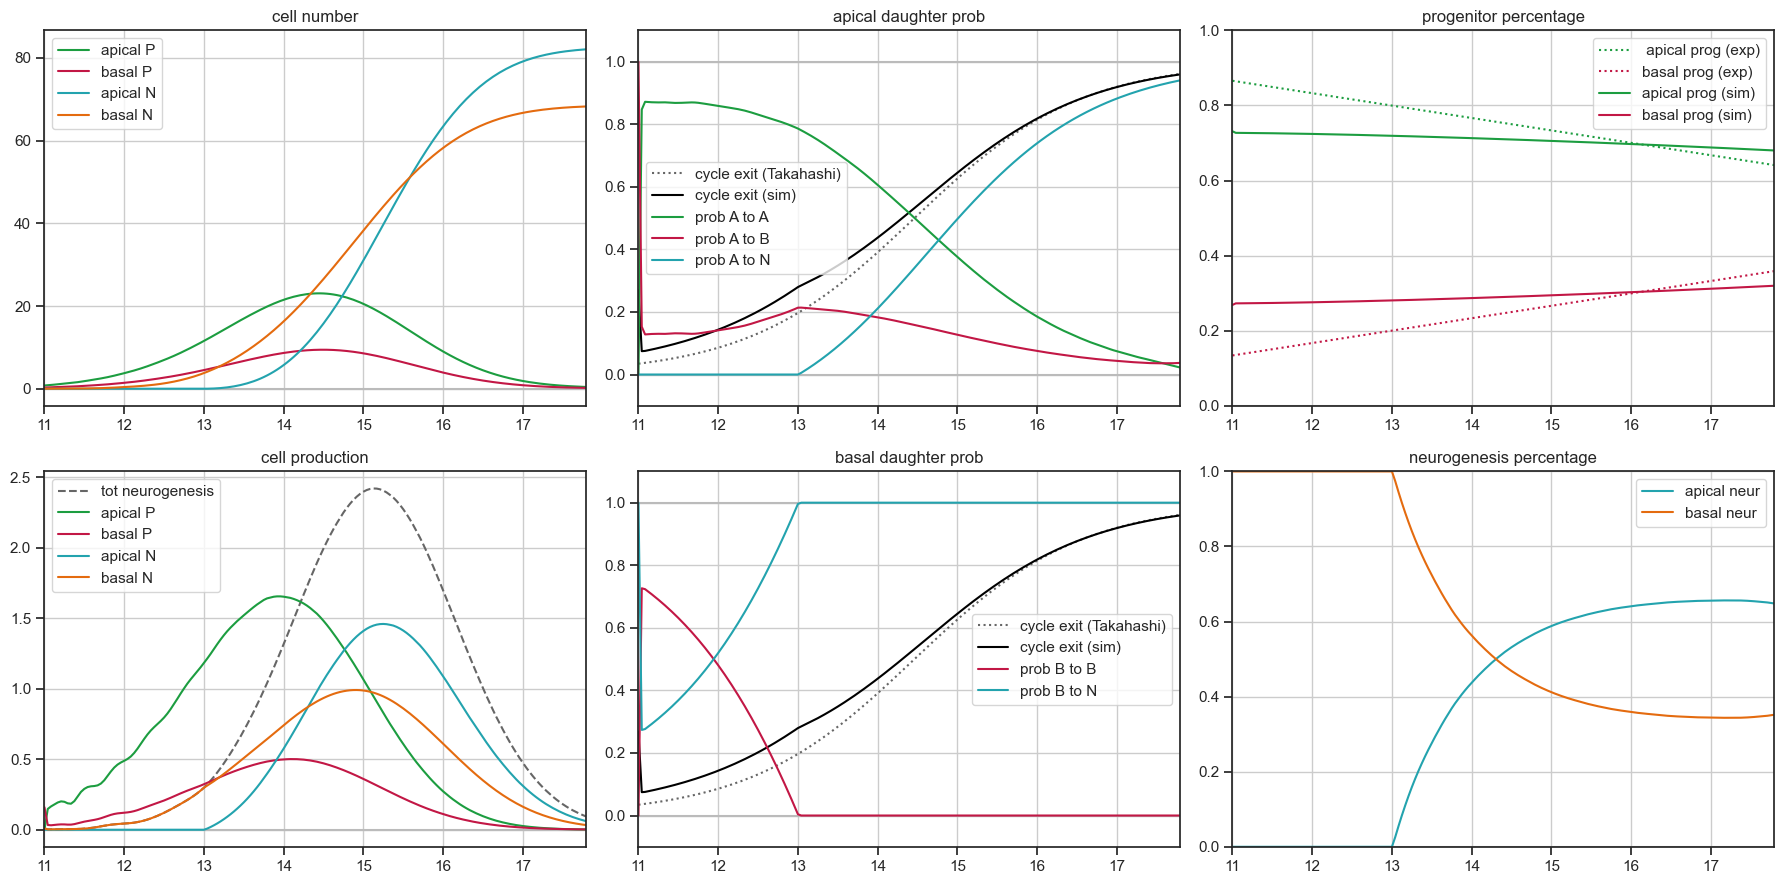

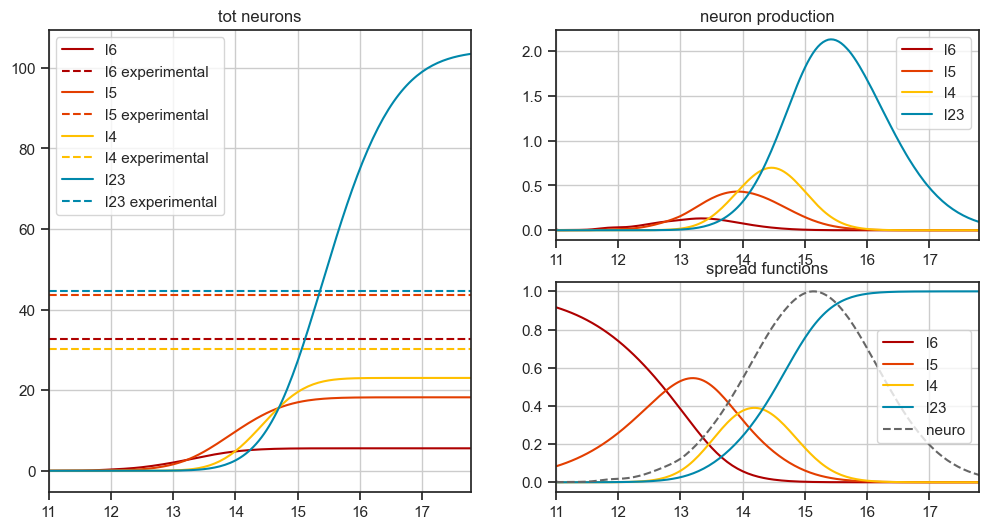

In [7]:
sim_raw_max = calc_sim_raw(CCL_max_fc)

# D-I

In [8]:
def calc_sim_D_I(b_ccl_fc = CCL_lin_fc):
    a0_perc = 0.975

    # sigmoid cell cycle exit
    x0_pE = 3.136
    k_pE = 1.714
    start_pE= 0.31
    test_pE_fc = lambda x: 1/(1 + np.exp(-k_pE*(x - x0_pE)))*(1-start_pE) + start_pE

    # sigmoid basal production from apical
    test_pA_to_B_fc = lambda x: 1/(1 + np.exp(-0.962*(x-3.762)))

    # sigmoid neuron production from basal
    start_pB_to_N_fc = 0.7
    test_pB_to_N_fc = lambda x: 1/(1 + np.exp(-1.443*(x-2.808)))*(1-start_pB_to_N_fc) + start_pB_to_N_fc


    sim_D_I = CellSimulation(
                n_aP0=a0_perc, n_bP0=1-a0_perc,
                b_cycle_length=b_ccl_fc,

                layers_dist=layers_gaus_coef,
                layers_perc=layers_density,

                min_per_frame=simulation_resolution,
                # cell cycle exit just from aP and faster curve to get earlier neurogenesis peak
                pE_fc = test_pE_fc,

                pA_to_B_fc = test_pA_to_B_fc,

                pB_to_N_fc = test_pB_to_N_fc
                )

    sim_D_I.run()

    sim_D_I.plot()

    sim_D_I.plot_layers()

    return sim_D_I

## D-I - linear

calculation: 100%|██████████| 192/192 [00:12<00:00, 15.98it/s]


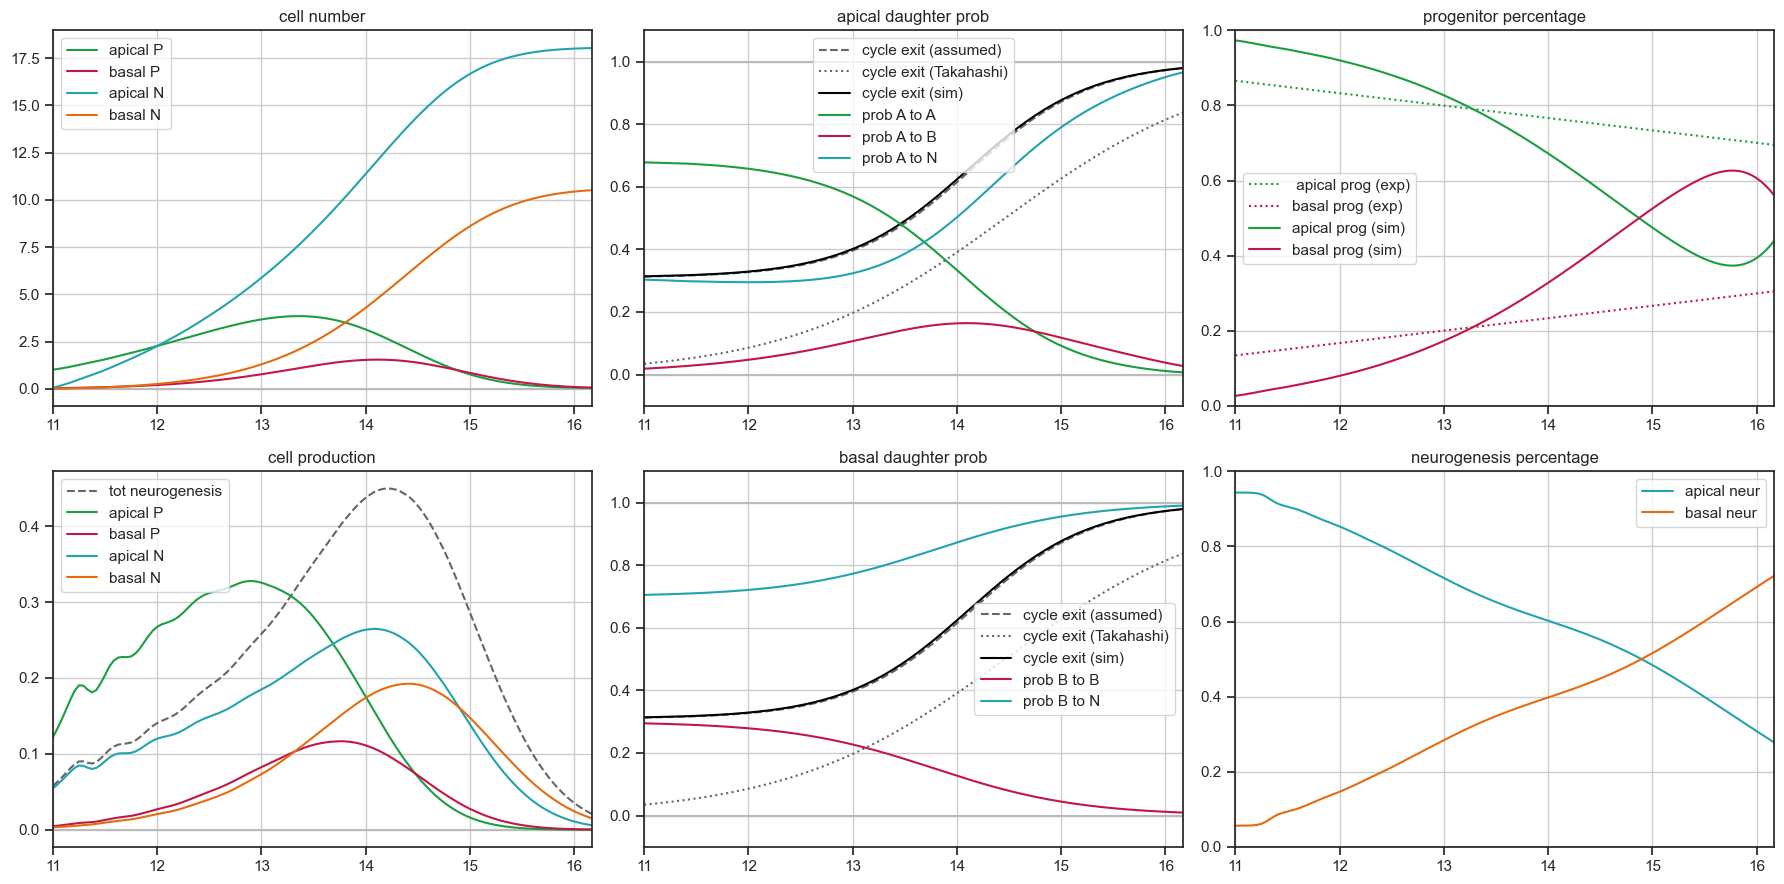

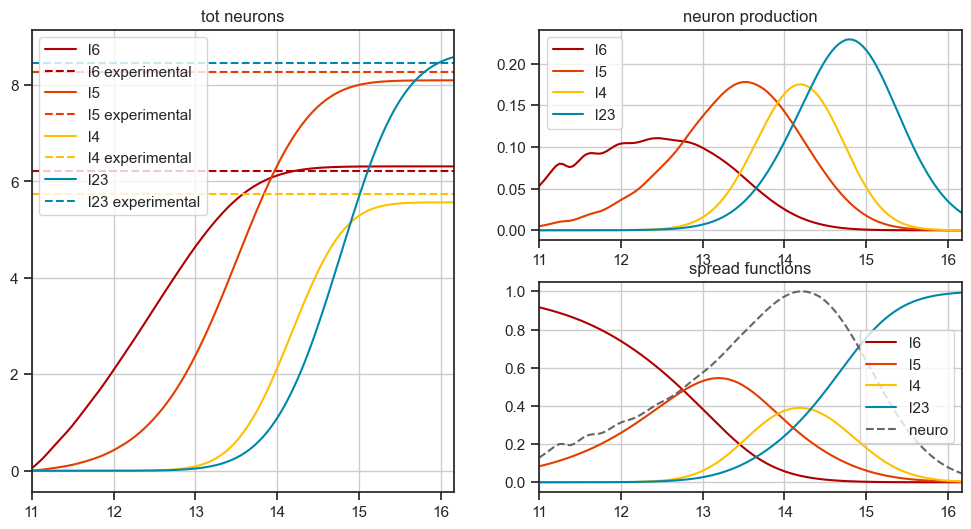

In [9]:
sim_D_I = calc_sim_D_I()

## D-I - min

apical setup:   0%|          | 0/192 [00:00<?, ?it/s]

calculation: 100%|██████████| 192/192 [00:12<00:00, 16.00it/s]


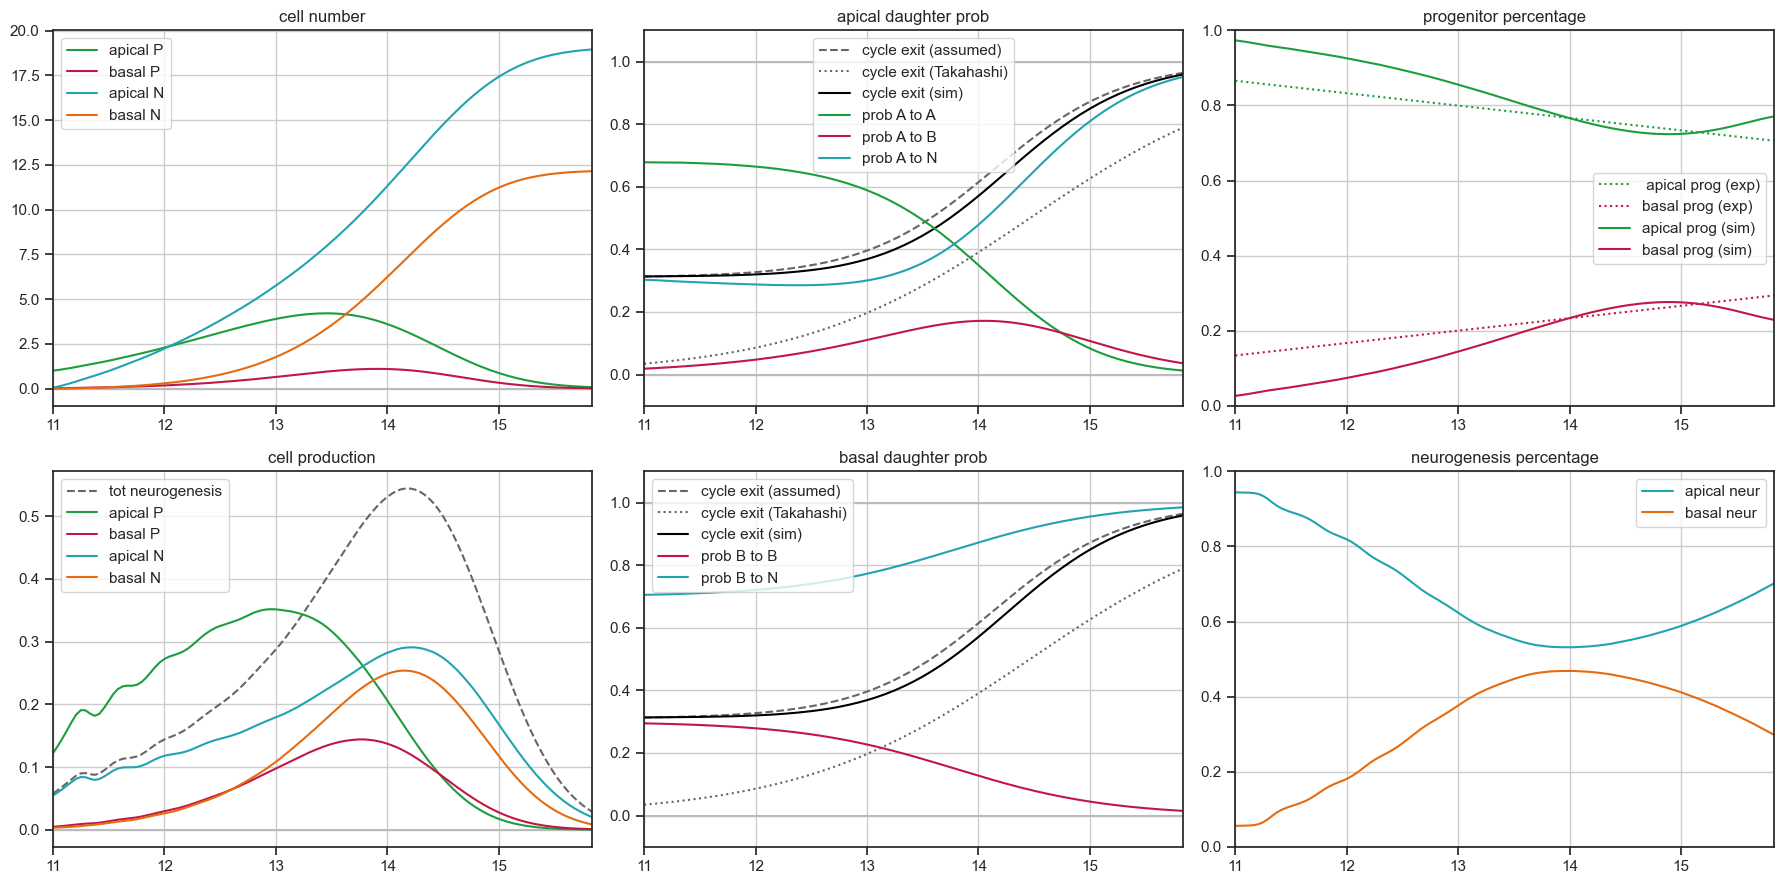

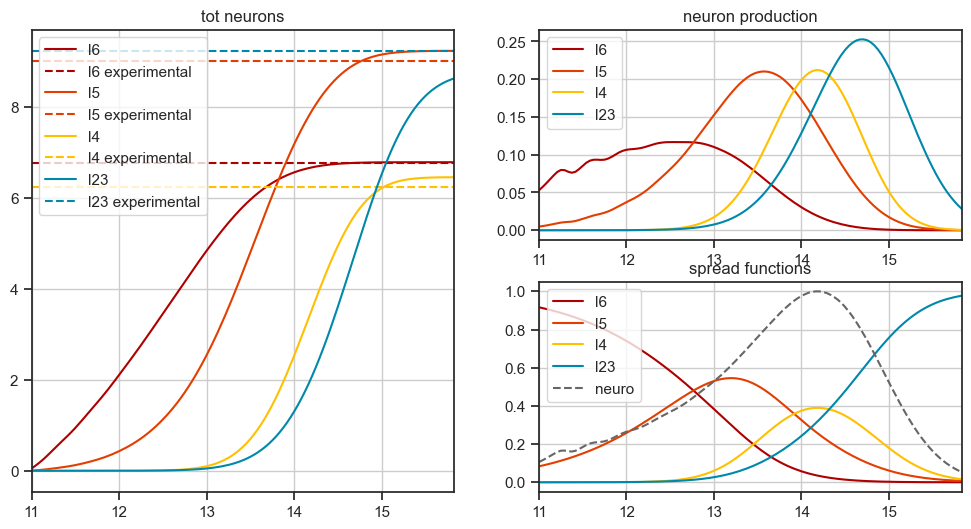

In [10]:
sim_D_I_min = calc_sim_D_I(CCL_min_fc)

## D-I - avg

calculation: 100%|██████████| 192/192 [00:12<00:00, 15.87it/s]


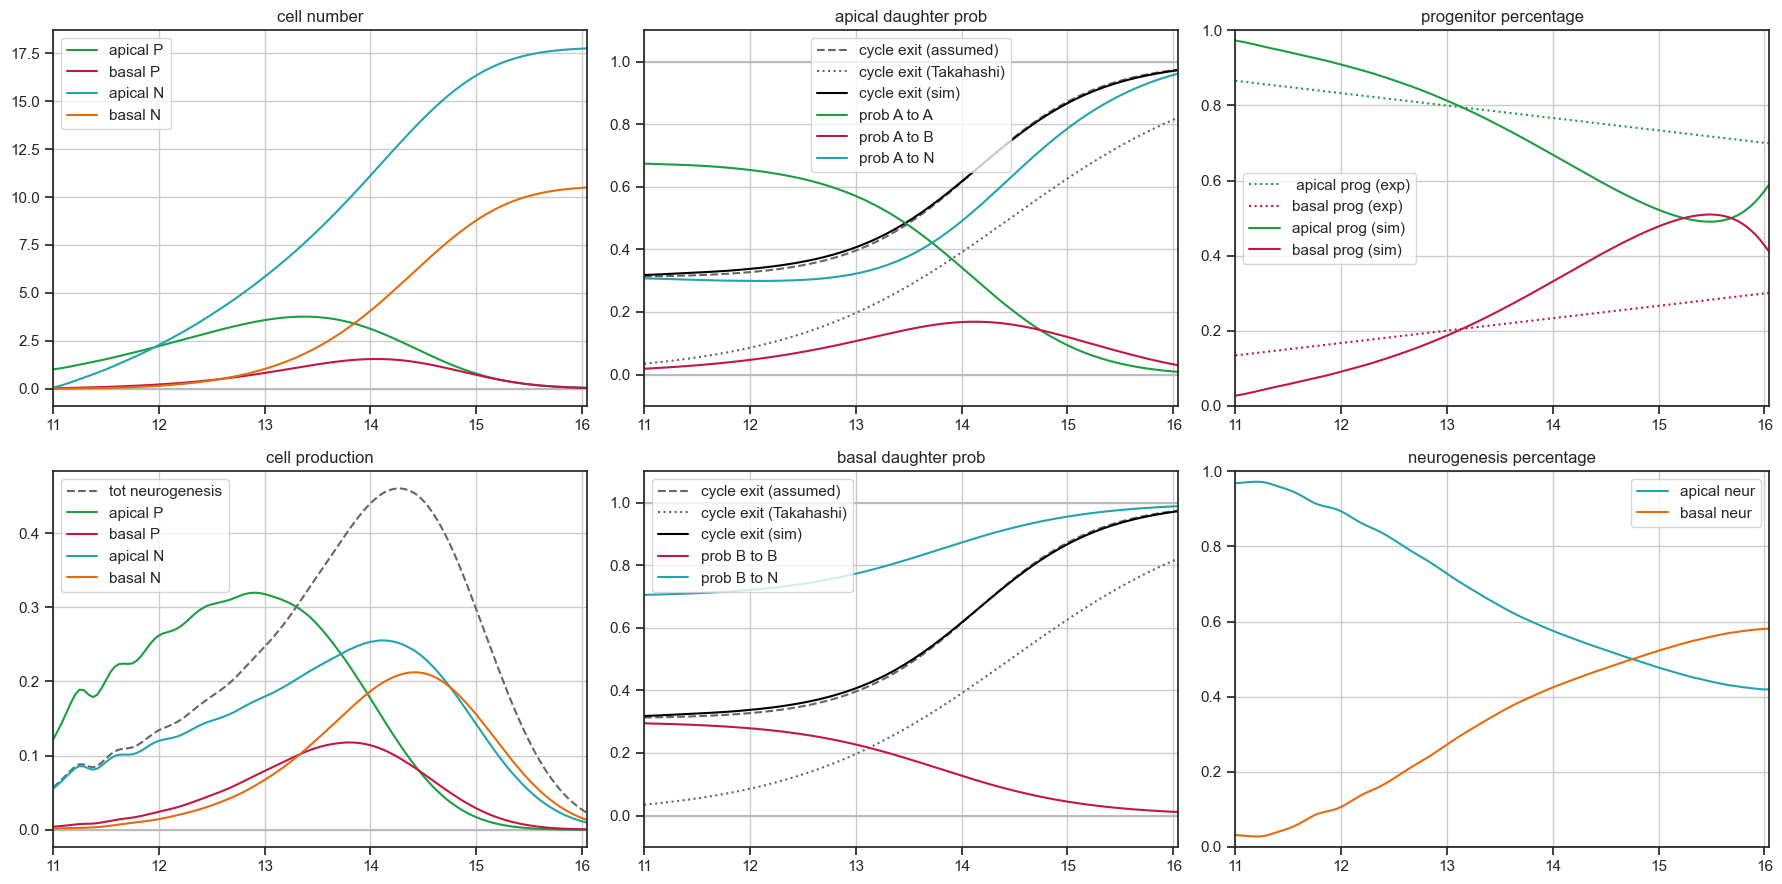

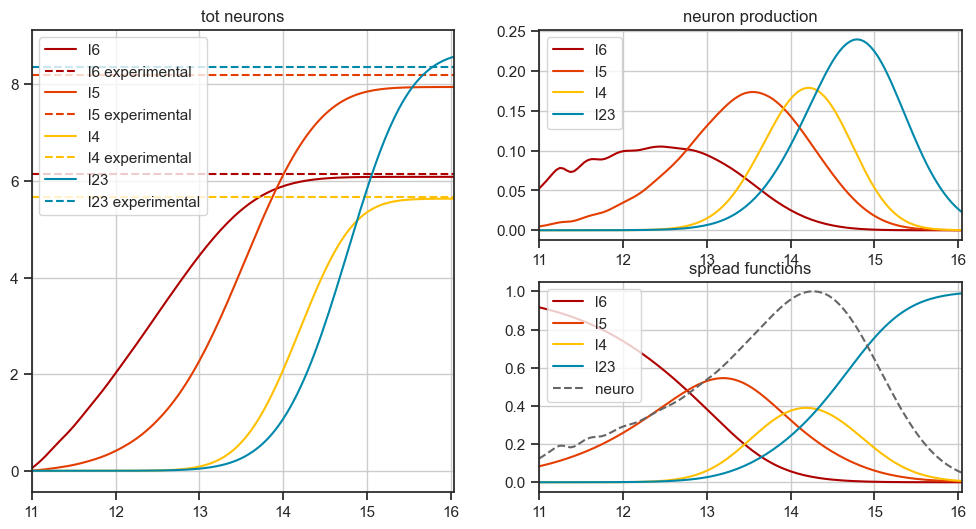

In [11]:
sim_D_I_avg = calc_sim_D_I(CCL_avg_fc)

## D-I - max

calculation: 100%|██████████| 192/192 [00:12<00:00, 15.92it/s]


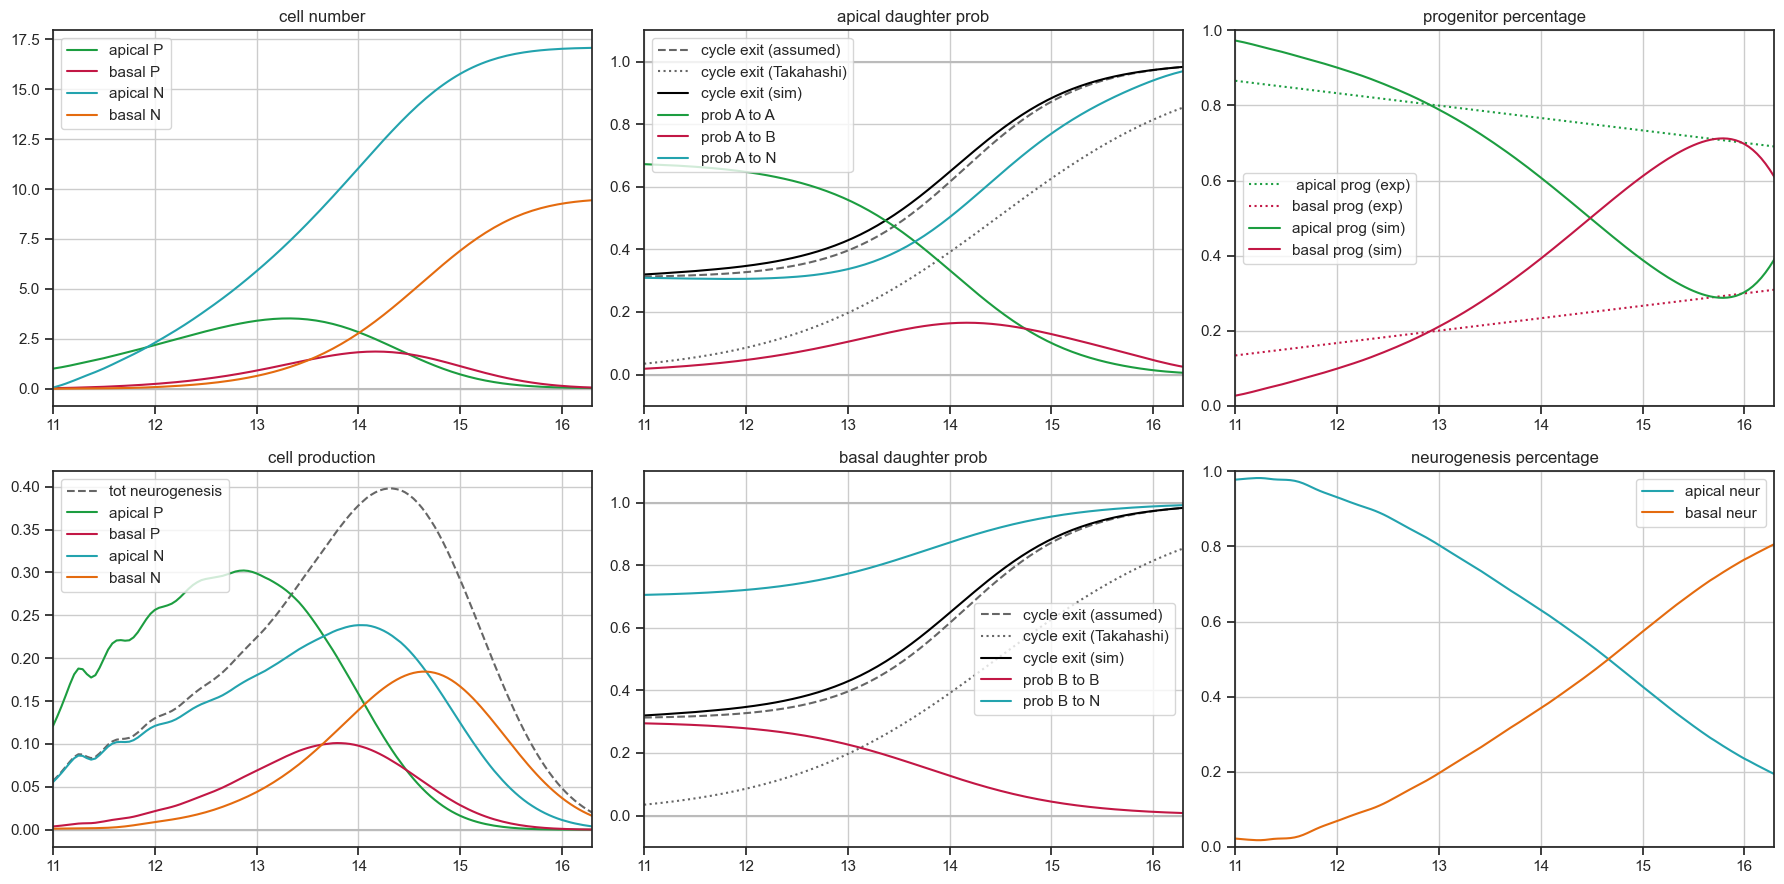

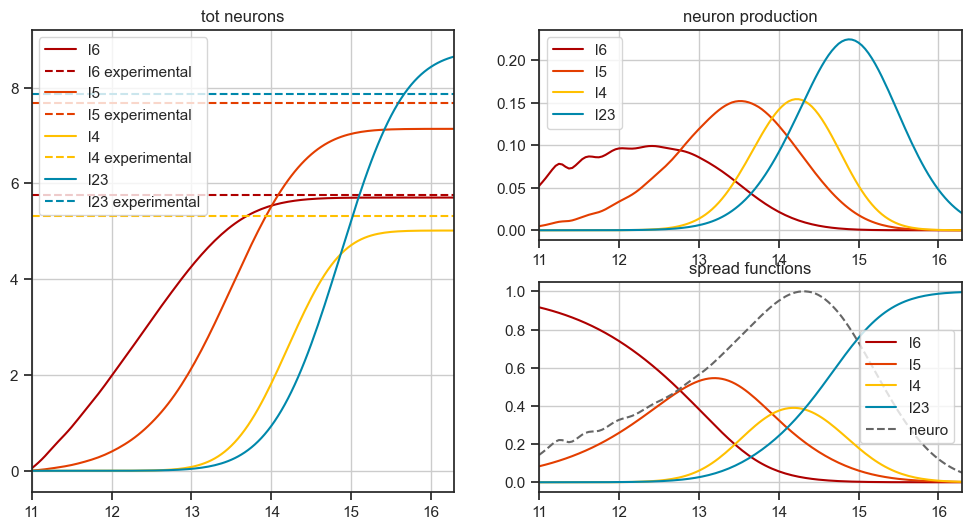

In [12]:
sim_D_I_max = calc_sim_D_I(CCL_max_fc)

# I-D

In [13]:
def calc_sim_I_D(b_ccl_fc = CCL_lin_fc):

    # cell cycle exit sigmoid parameters
    x0 = 2.78
    k = 1.058
    start = 0.167

    # starting percentage of apical progenitors
    a0_perc = 0.866

    sim_I_D = CellSimulation(
                n_aP0=a0_perc, n_bP0=1-a0_perc,
                b_cycle_length=b_ccl_fc,

                pE_fc = lambda x: 1/(1 + np.exp(-k*(x-x0)))*(1-start) + start,

                min_per_frame=simulation_resolution,

                layers_dist=layers_gaus_coef,
                layers_perc=layers_density,
                clip_prob=True)

    sim_I_D.run()

    sim_I_D.plot()

    sim_I_D.plot_layers()

    return sim_I_D

## I-D - linear

calculation: 100%|██████████| 192/192 [00:19<00:00,  9.93it/s]


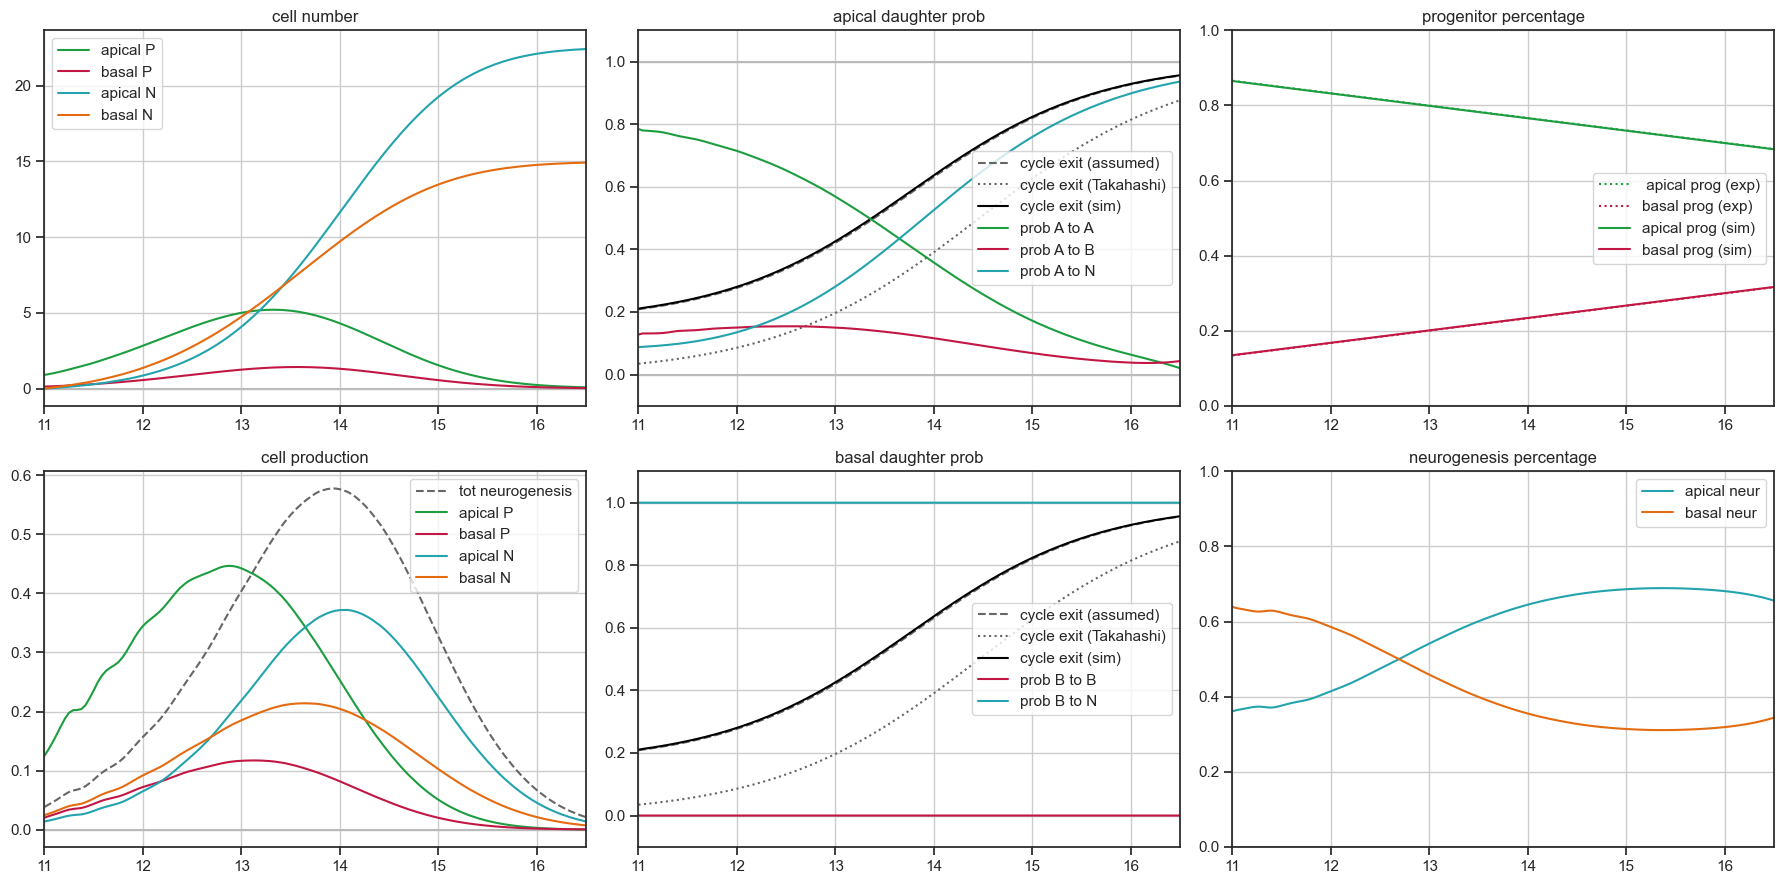

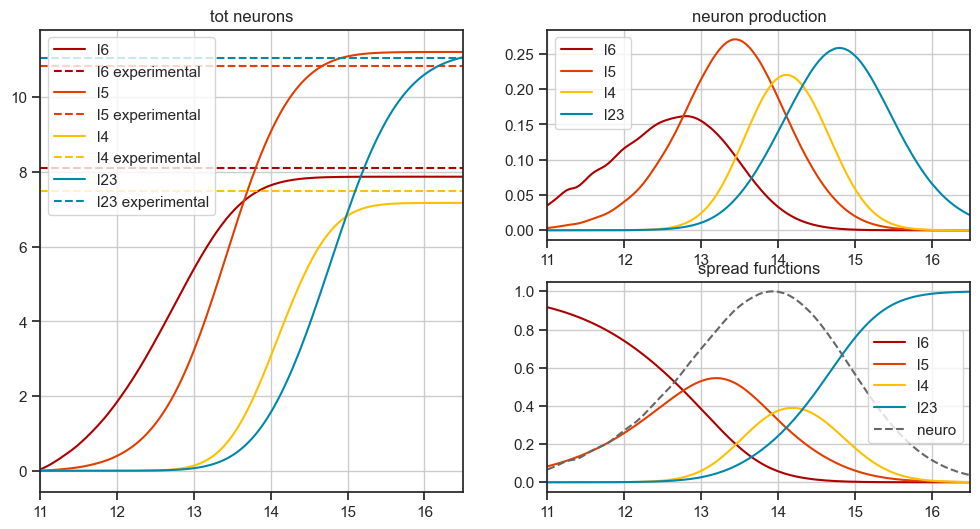

In [14]:
sim_I_D = calc_sim_I_D()

## I-D - min

calculation: 100%|██████████| 192/192 [00:21<00:00,  9.10it/s]


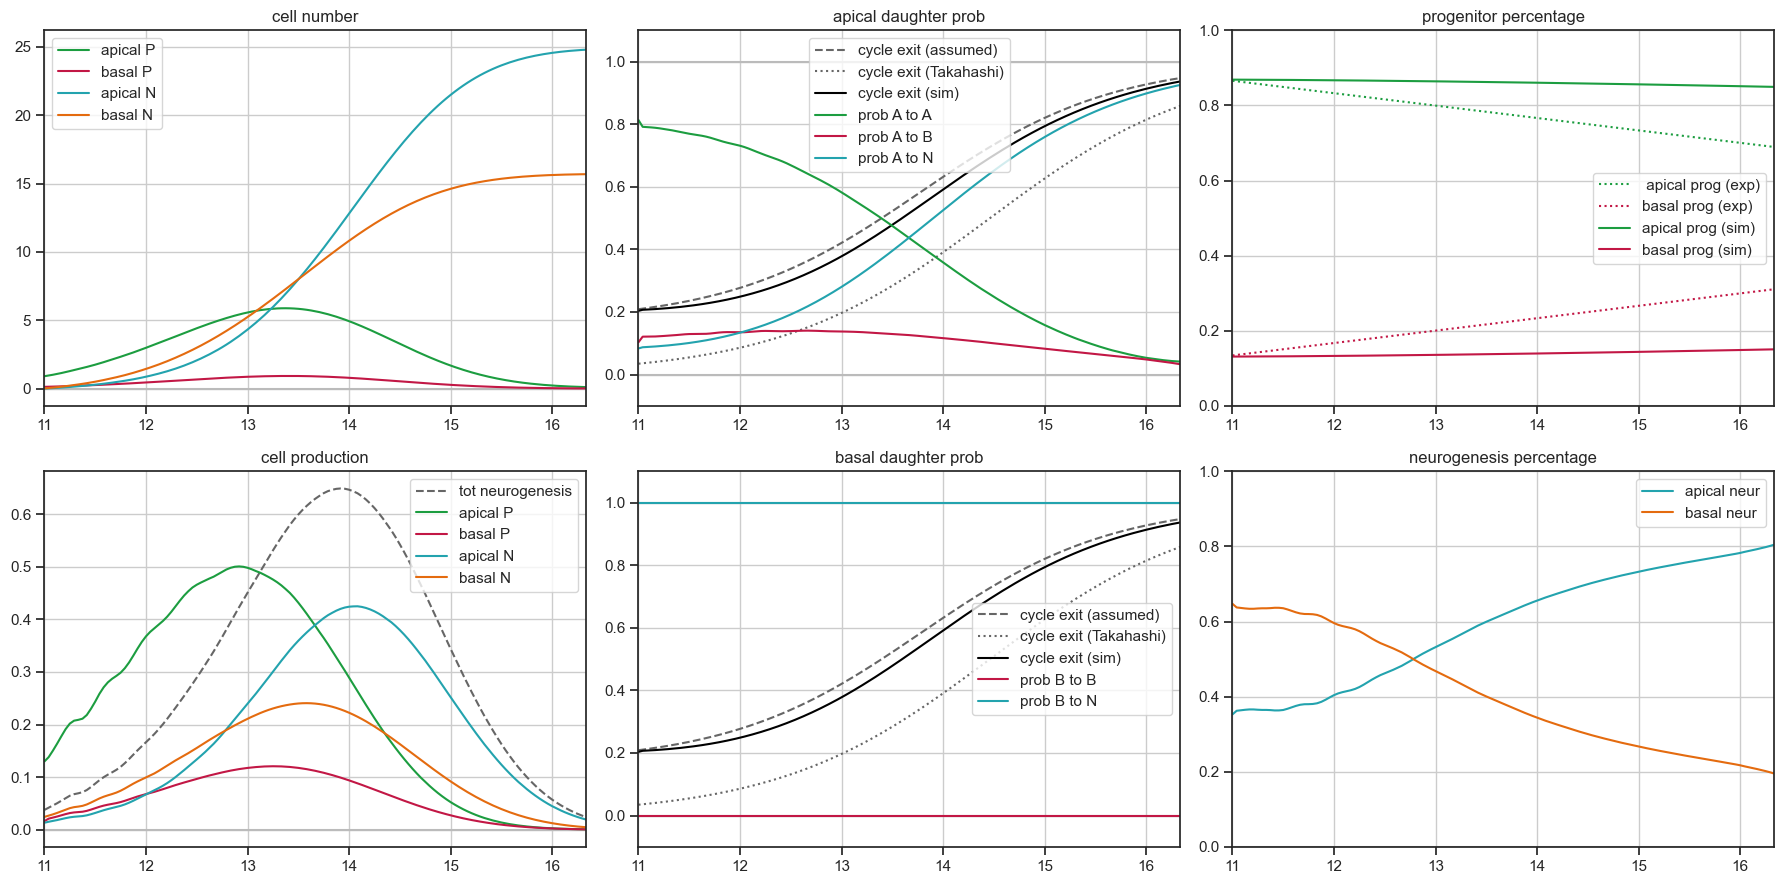

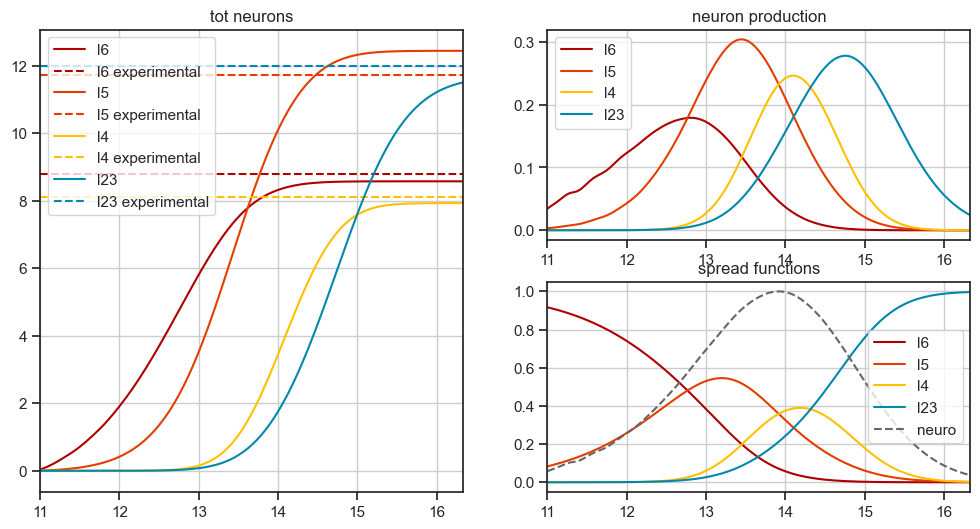

In [15]:
sim_I_D_min = calc_sim_I_D(CCL_min_fc)

## I-D - avg

calculation: 100%|██████████| 192/192 [00:21<00:00,  8.98it/s]


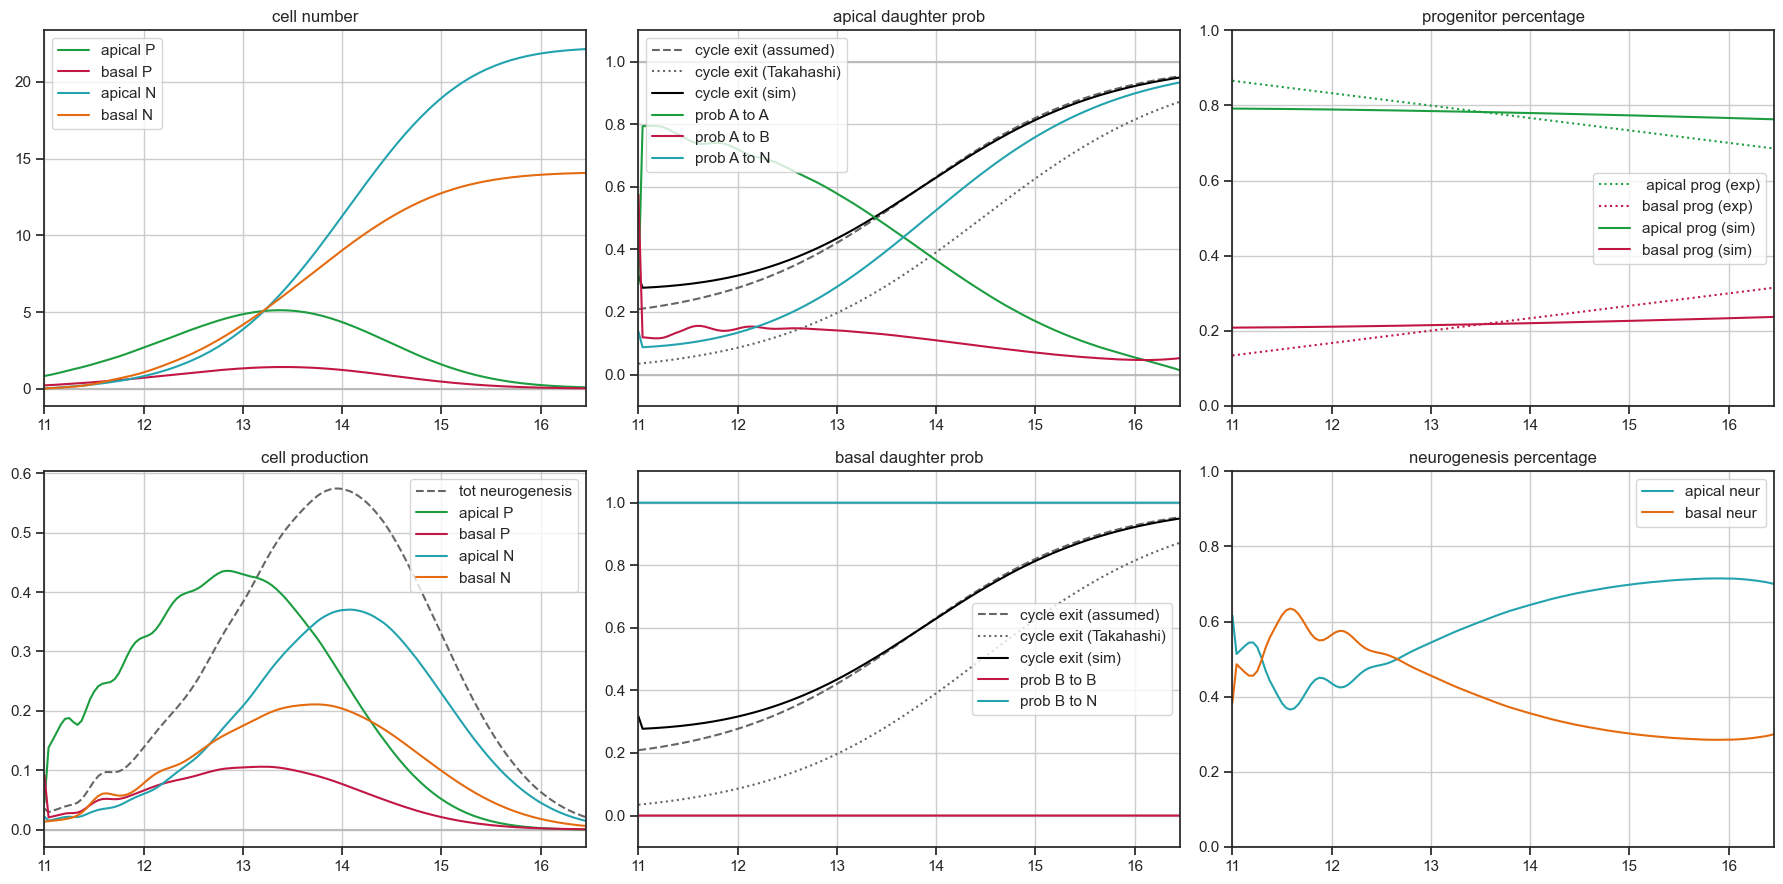

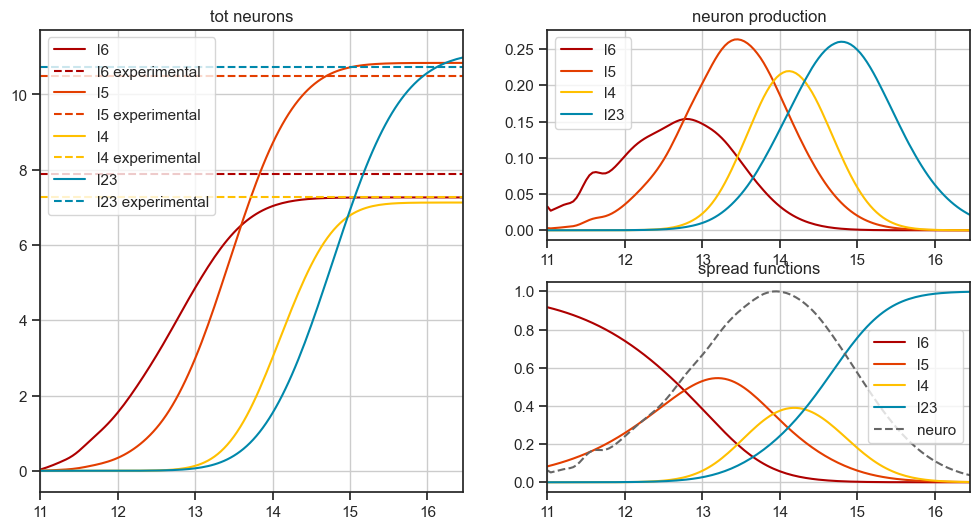

In [16]:
sim_I_D_avg = calc_sim_I_D(CCL_avg_fc)

## I-D - max

calculation: 100%|██████████| 192/192 [00:20<00:00,  9.25it/s]


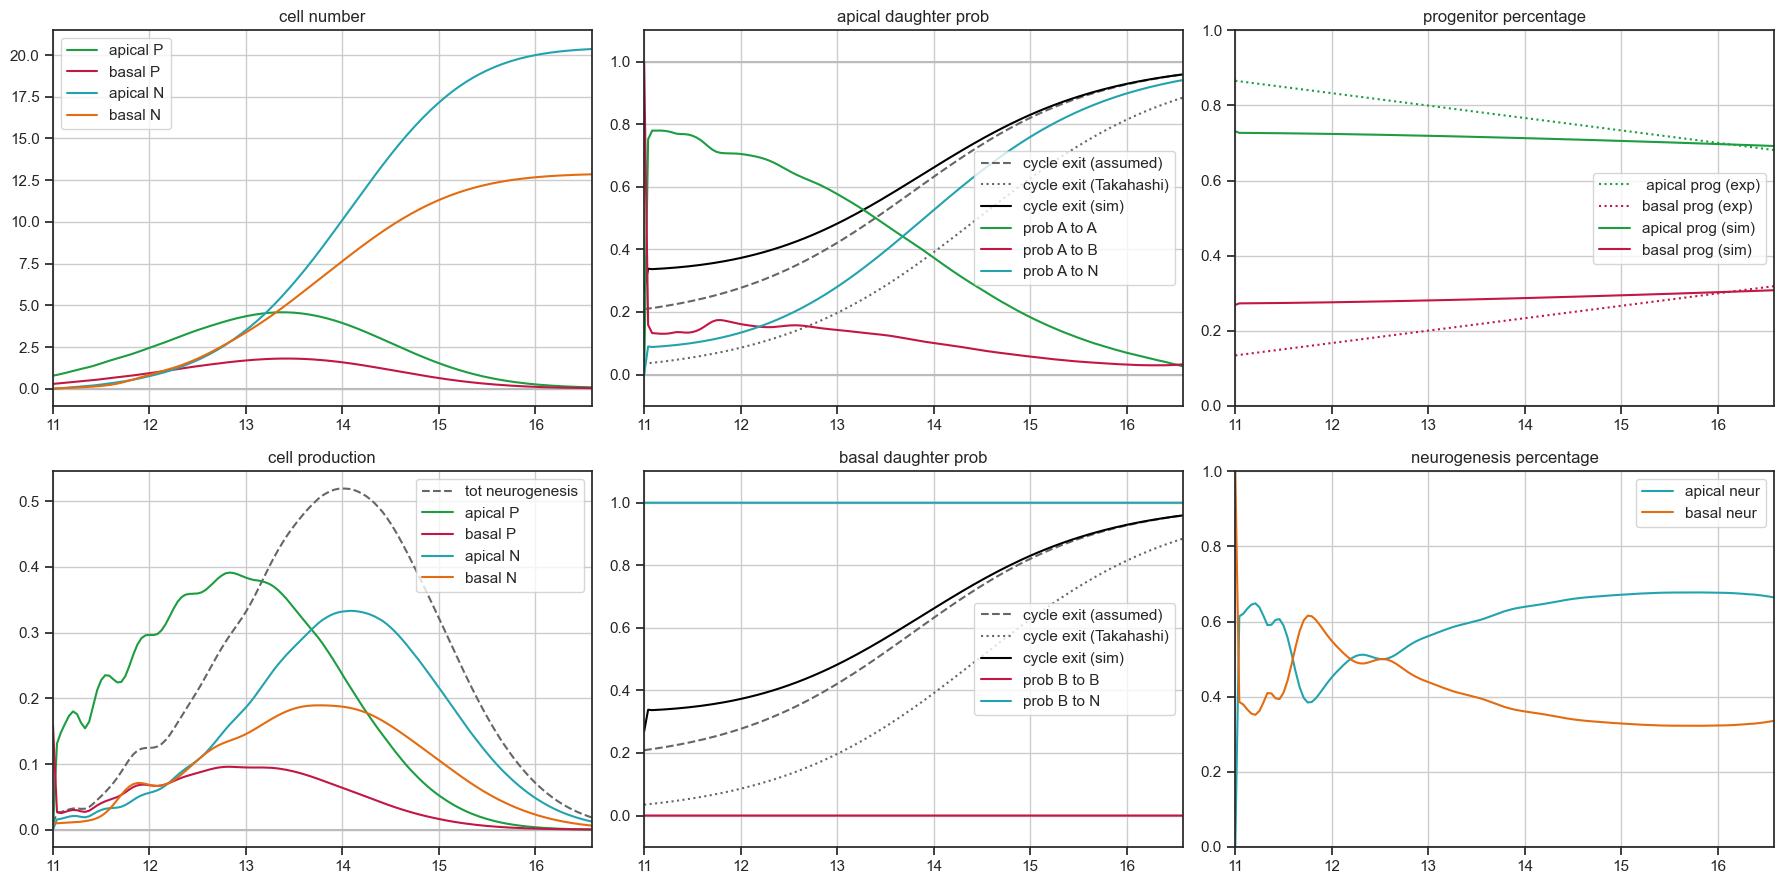

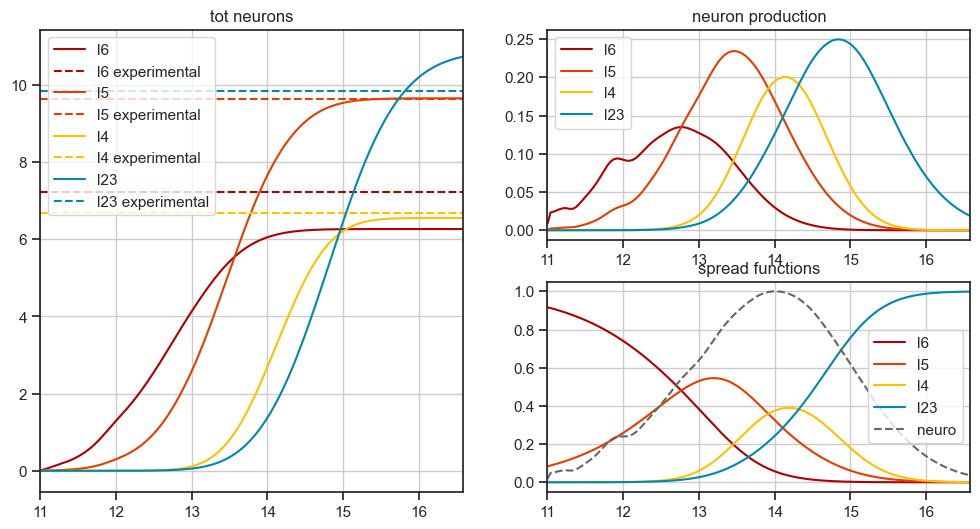

In [17]:
sim_I_D_max = calc_sim_I_D(CCL_max_fc)

# plots

In [18]:
sim_names = ['Raw_linear', 'Raw_min', 'Raw_avg', 'Raw_max',
             'D_I_linear', 'D_I_min', 'D_I_avg', 'D_I_max',
             'I_D_linear', 'I_D_min', 'I_D_avg', 'I_D_max']

sims = [sim_raw, sim_raw_min, sim_raw_avg, sim_raw_max,
        sim_D_I, sim_D_I_min, sim_D_I_avg, sim_D_I_max,
        sim_I_D, sim_I_D_min, sim_I_D_avg, sim_I_D_max]

metrics_dicts = []
tables_dict = {}

for i, sim in enumerate(sims):
    metrics_dict = sim.get_metrics()
    metrics_dict['source'] = sim_names[i]
    metrics_dicts.append(metrics_dict)
    
    tables_dict[sim_names[i]] = sim.get_tables()

metrics_df = pd.DataFrame(metrics_dicts)

### start and end of neurogenesis

In [19]:
metrics_source = metrics_df['source'].values

# let's get the end point (neurons > 99.5%)
end_points_values = metrics_df['end_point'].values

end_points_dict = dict(zip(metrics_source, end_points_values))

# let's get the end point (neurons < 0.5%)
start_points_values = metrics_df['start_point'].values

start_points_dict = dict(zip(metrics_source, start_points_values))

### days vector

In [20]:
days_vc = tables_dict['Raw_linear']['days']

In [21]:
sim_names_np = np.array(sim_names).reshape(3,4).T

sim_np = np.array(sims).reshape(3,4).T

In [22]:
sim_names_np

array([['Raw_linear', 'D_I_linear', 'I_D_linear'],
       ['Raw_min', 'D_I_min', 'I_D_min'],
       ['Raw_avg', 'D_I_avg', 'I_D_avg'],
       ['Raw_max', 'D_I_max', 'I_D_max']], dtype='<U10')

## percentage progenitors

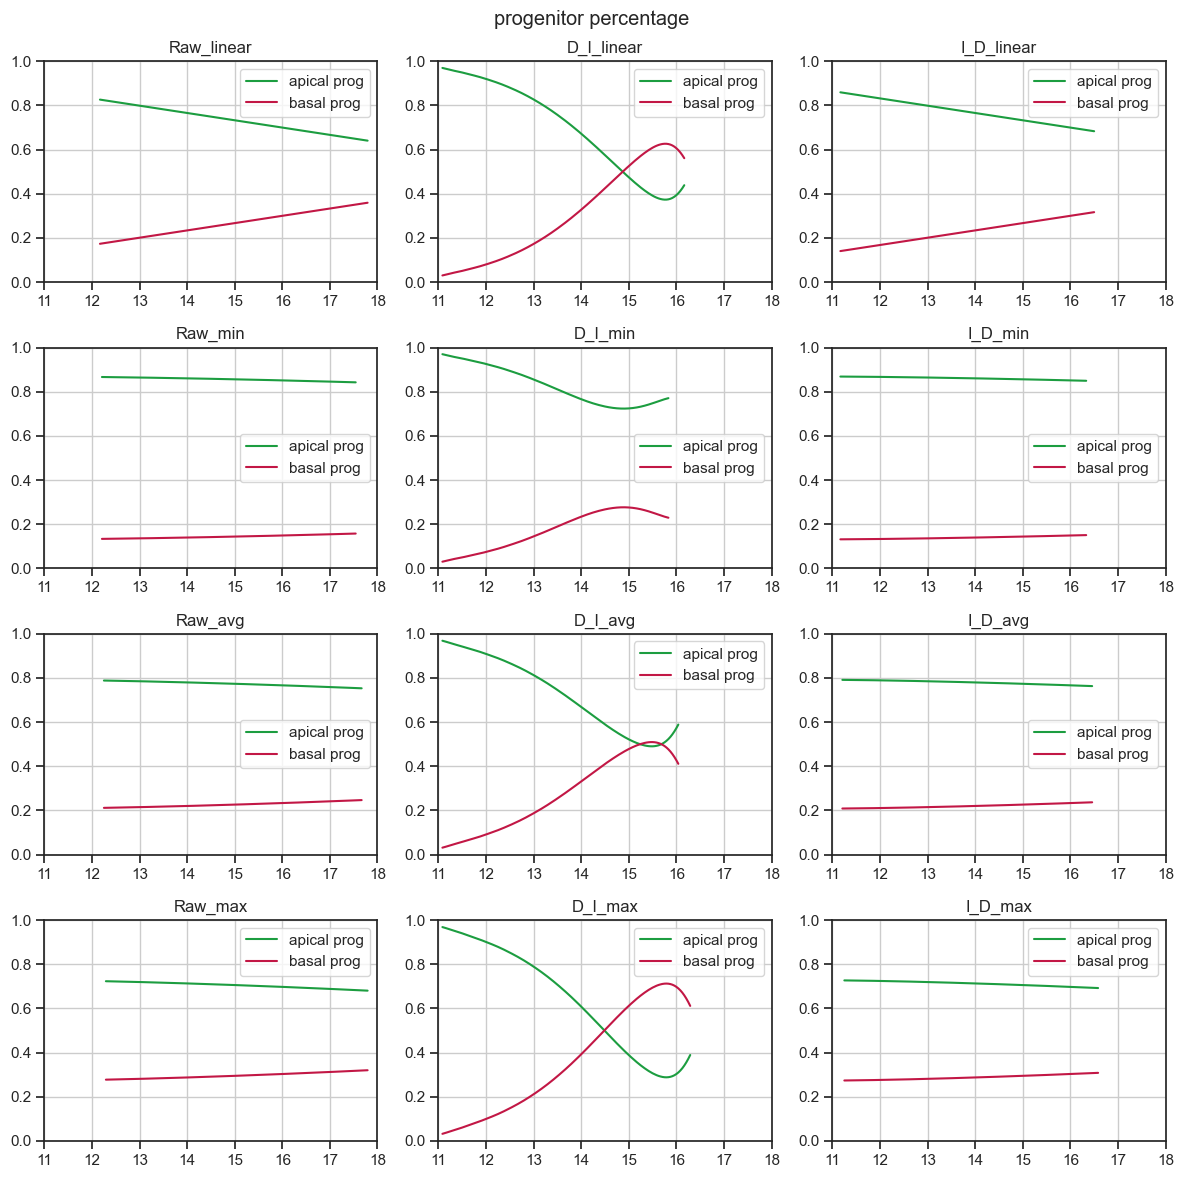

In [23]:
k = len(sims)

rows = 4
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))



for i in range(rows):
    for j in range(cols):
        ax = axes[i,j]

        s = sim_names_np[i,j]

        x = days_vc.copy()

        prog_n = tables_dict[s]['n_cells'][:2]

        # perc_a
        y = prog_n[0] / np.sum(prog_n, axis = 0)


        current_start = start_points_dict[s]
        current_end = end_points_dict[s]

        y[x<current_start] = None
        y[x>current_end] = None

        ax.plot(x, y, color = neuro_colors_dict['apical P'], label = 'apical prog')
        ax.plot(x, 1-y, color = neuro_colors_dict['basal P'], label = 'basal prog')
        ax.set_title(f'{s}')

        ax.set_xlim([11,18])
        ax.set_ylim([0,1])

        ax.legend()
        ax.grid()


plt.suptitle('progenitor percentage')
plt.tight_layout()

plt.show()

### D_I min

it has reasonable progenitor ration

### D_I avg and D_I max

have same problem as the linear

## cell cycle length

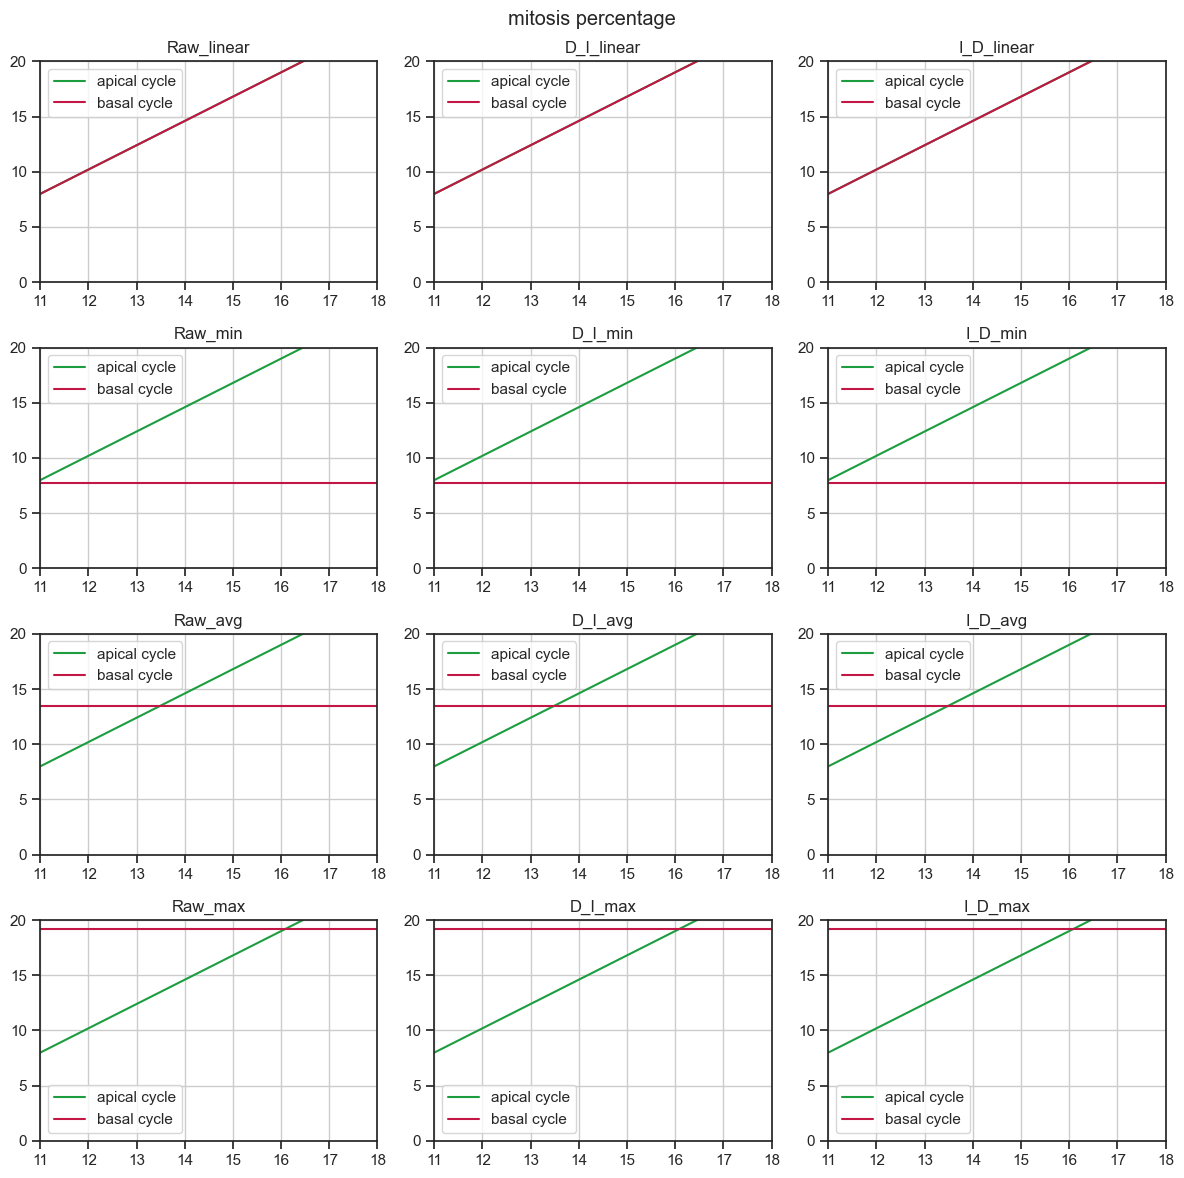

In [24]:
k = len(sims)

rows = 4
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))



for i in range(rows):
    for j in range(cols):
        ax = axes[i,j]

        s = sim_names_np[i,j]

        x = days_vc.copy()

        y_a = tables_dict[s]['cycle_length'][0]
        y_b = tables_dict[s]['cycle_length'][1]

        current_start = start_points_dict[s]
        current_end = end_points_dict[s]

        # y[x<current_start] = None
        # y[x>current_end] = None

        ax.plot(x, y_a, color = neuro_colors_dict['apical P'],  label = 'apical cycle')
        ax.plot(x, y_b, color = neuro_colors_dict['basal P'], label = 'basal cycle')
        ax.set_title(f'{s}')

        ax.set_xlim([11,18])
        ax.set_ylim([0,20])

        ax.legend()
        ax.grid()


plt.suptitle('mitosis percentage')
plt.tight_layout()

plt.show()

In [25]:
sim_to_skip = ['Raw_linear', 'D_I_linear', 'I_D_linear']

sim_names_new_np = sim_names_np[1:]
sim_names_new_np

array([['Raw_min', 'D_I_min', 'I_D_min'],
       ['Raw_avg', 'D_I_avg', 'I_D_avg'],
       ['Raw_max', 'D_I_max', 'I_D_max']], dtype='<U10')

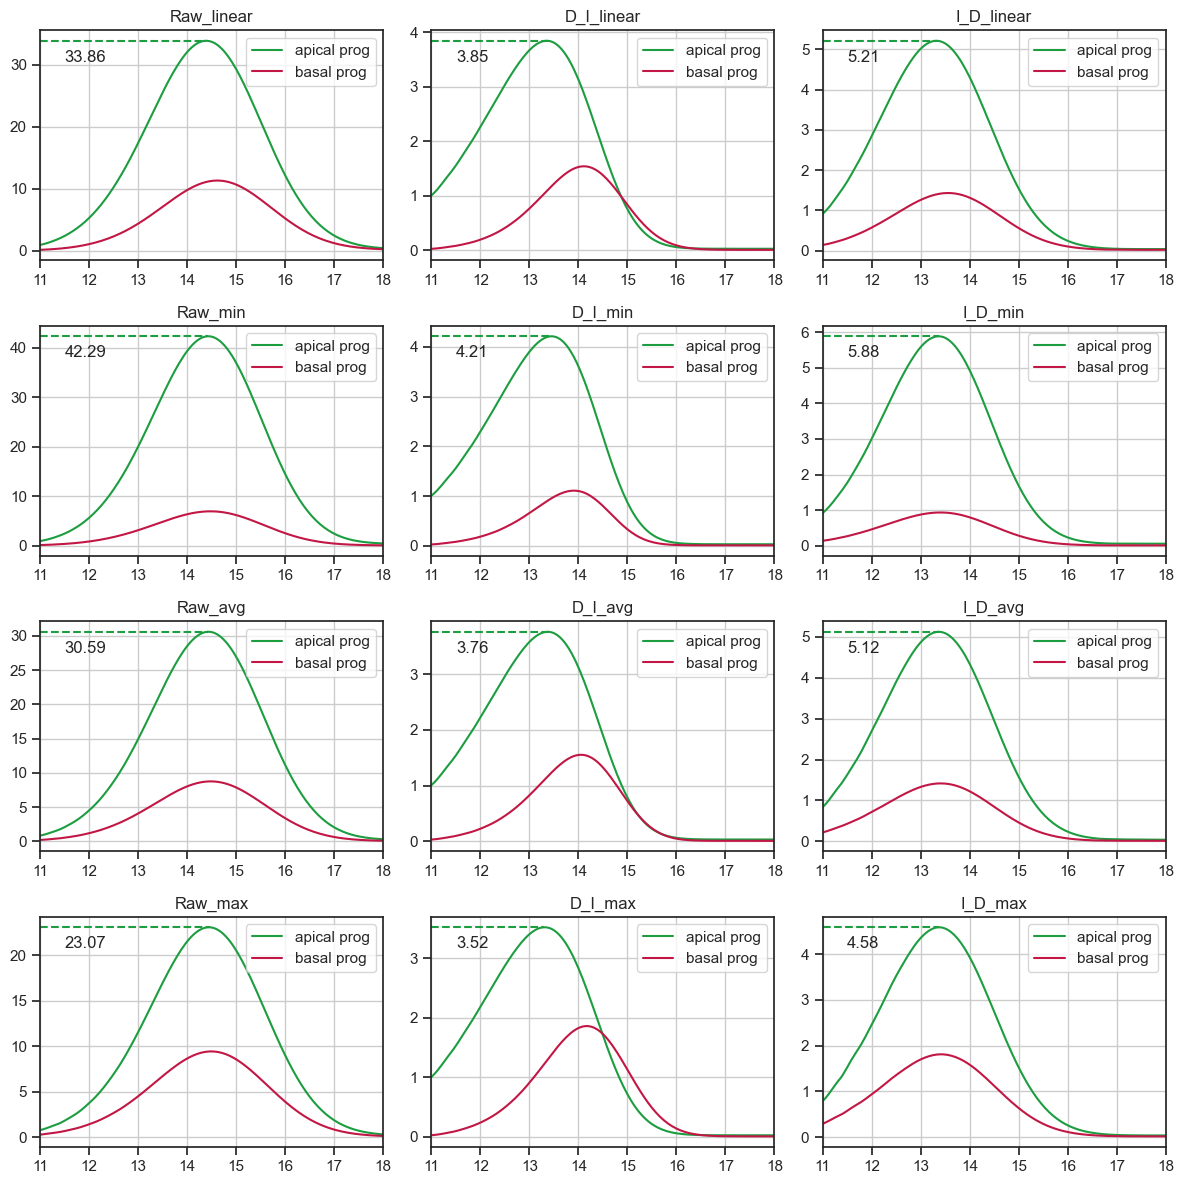

In [26]:
k = len(sims)

rows = 4
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))



for i in range(rows):
    for j in range(cols):
        ax = axes[i,j]

        s = sim_names_np[i,j]

        x = days_vc

        prog_n = tables_dict[s]['n_cells'][:2]

        # perc_a
        y_a = prog_n[0]
        y_b = prog_n[1]


        current_start = start_points_dict[s]
        current_end = end_points_dict[s]

        y[x<current_start] = None
        y[x>current_end] = None

        ax.plot(x, y_a, color = neuro_colors_dict['apical P'], label = 'apical prog')
        ax.hlines(y = np.max(y_a), xmin = 11, xmax = x[np.argmax(y_a)], color = neuro_colors_dict['apical P'], linestyle = '--')
        ax.text(x = 11.5, y = 0.9 * np.max(y_a), s = f'{np.max(y_a):.2f}')
        ax.plot(x, y_b, color = neuro_colors_dict['basal P'], label = 'basal prog')
        ax.set_title(f'{s}')

        ax.set_xlim([11,18])

        ax.legend()
        ax.grid()

plt.tight_layout()

plt.show()

## direct - indirect neurogenesis

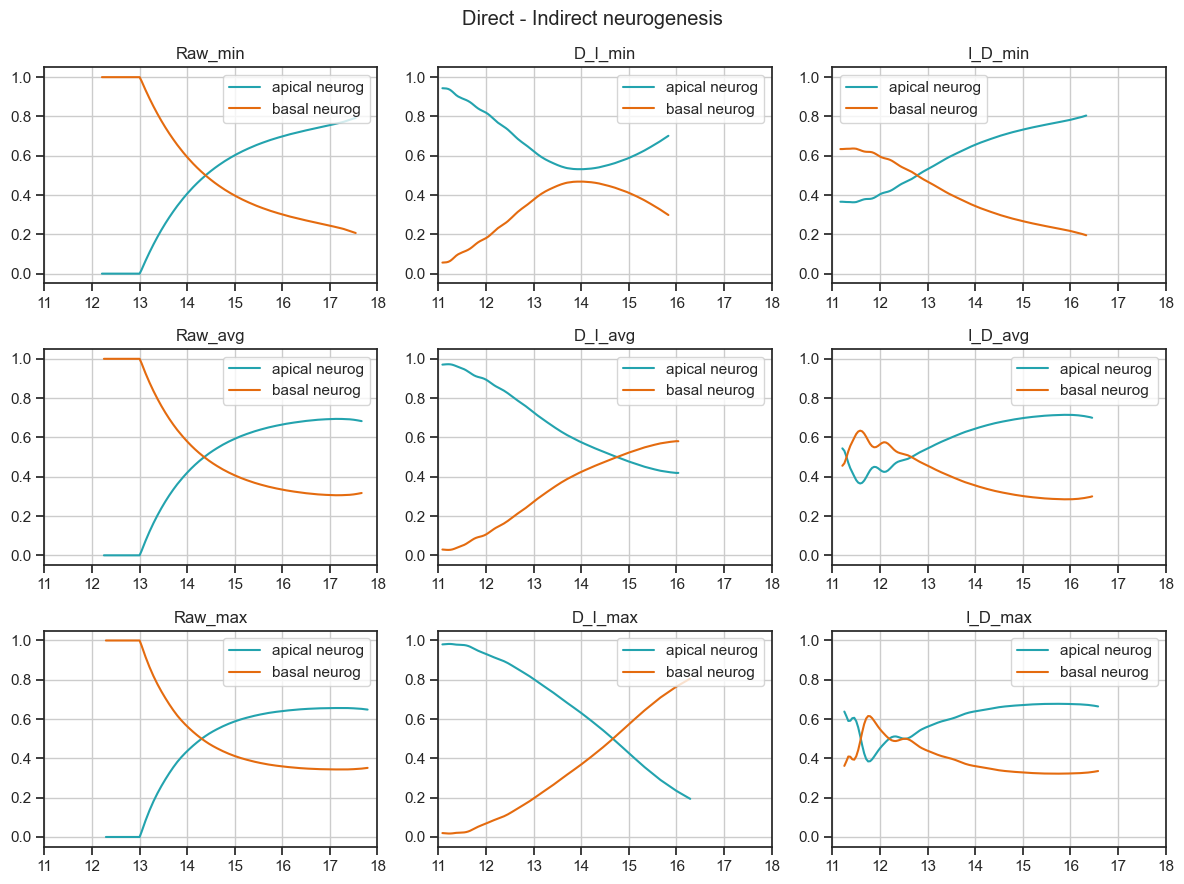

In [27]:
k = len(sims)

rows = 3
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))



for i in range(rows):
    for j in range(cols):
        ax = axes[i,j]

        s = sim_names_new_np[i,j]

        x = days_vc

        neurogenesis_n = tables_dict[s]['new_cells'][2:]

        # perc_a
        y = neurogenesis_n[0] / np.sum(neurogenesis_n, axis = 0)


        current_start = start_points_dict[s]
        current_end = end_points_dict[s]

        y[x<current_start] = None
        y[x>current_end] = None

        ax.plot(x, y, color = neuro_colors_dict['apical N'], label = 'apical neurog')
        ax.plot(x, 1-y, color = neuro_colors_dict['basal N'], label = 'basal neurog')
        ax.set_title(f'{s}')

        ax.set_xlim([11,18])
        ax.set_ylim([-0.05,1.05])

        ax.legend()
        ax.grid()

plt.suptitle('Direct - Indirect neurogenesis')
plt.tight_layout()


plt.show()

### D_I avg and D_I max

have reasonable Direct to Indirect curve

### I_D avg and I_D max

have no transition Indirect to Direct

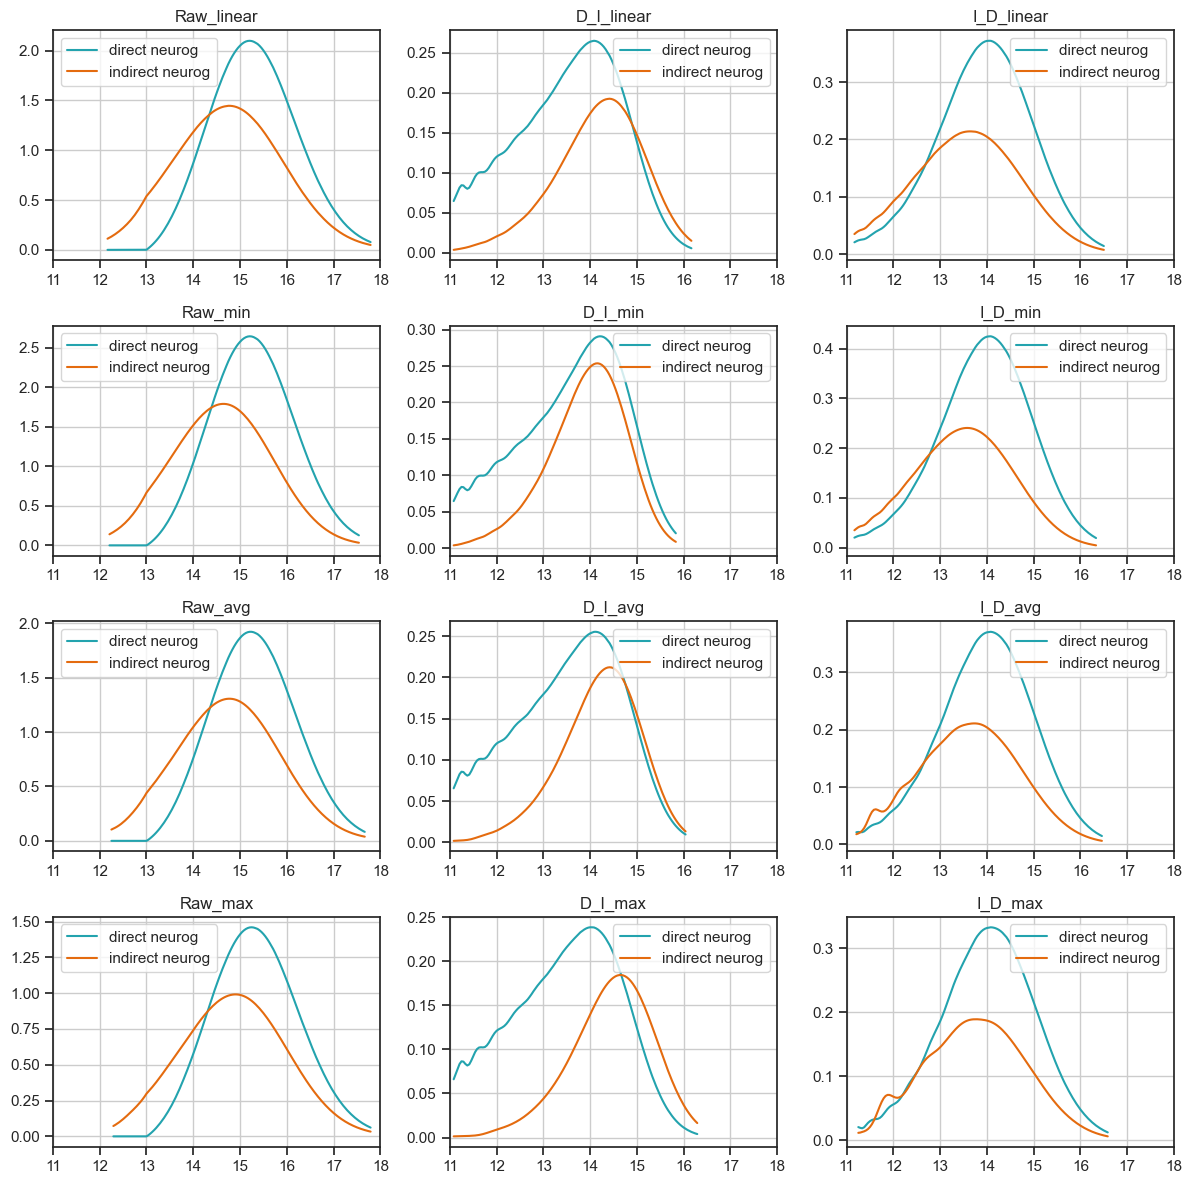

In [28]:
k = len(sims)

rows = 4
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))



for i in range(rows):
    for j in range(cols):
        ax = axes[i,j]

        s = sim_names_np[i,j]

        x = days_vc

        neurogenesis_n = tables_dict[s]['new_cells'][2:]

        # perc_a
        y_a = neurogenesis_n[0]
        y_b = neurogenesis_n[1]


        current_start = start_points_dict[s]
        current_end = end_points_dict[s]

        y_a[x<current_start] = None
        y_a[x>current_end] = None

        y_b[x<current_start] = None
        y_b[x>current_end] = None

        ax.plot(x, y_a, color = neuro_colors_dict['apical N'], label = 'direct neurog')
        ax.plot(x, y_b, color = neuro_colors_dict['basal N'], label = 'indirect neurog')
        ax.set_title(f'{s}')

        ax.set_xlim([11,18])

        ax.legend()
        ax.grid()

# hide any unused subplots if k < rows*cols
# for j in range(k, cols):
#     fig.delaxes(axes[j])

plt.tight_layout()

plt.show()

## pA_to_B and cell cycle exit

for Raw, D_I and I_D the cell cycle exit is fixed

for D_I the pA_to_B is also fixed

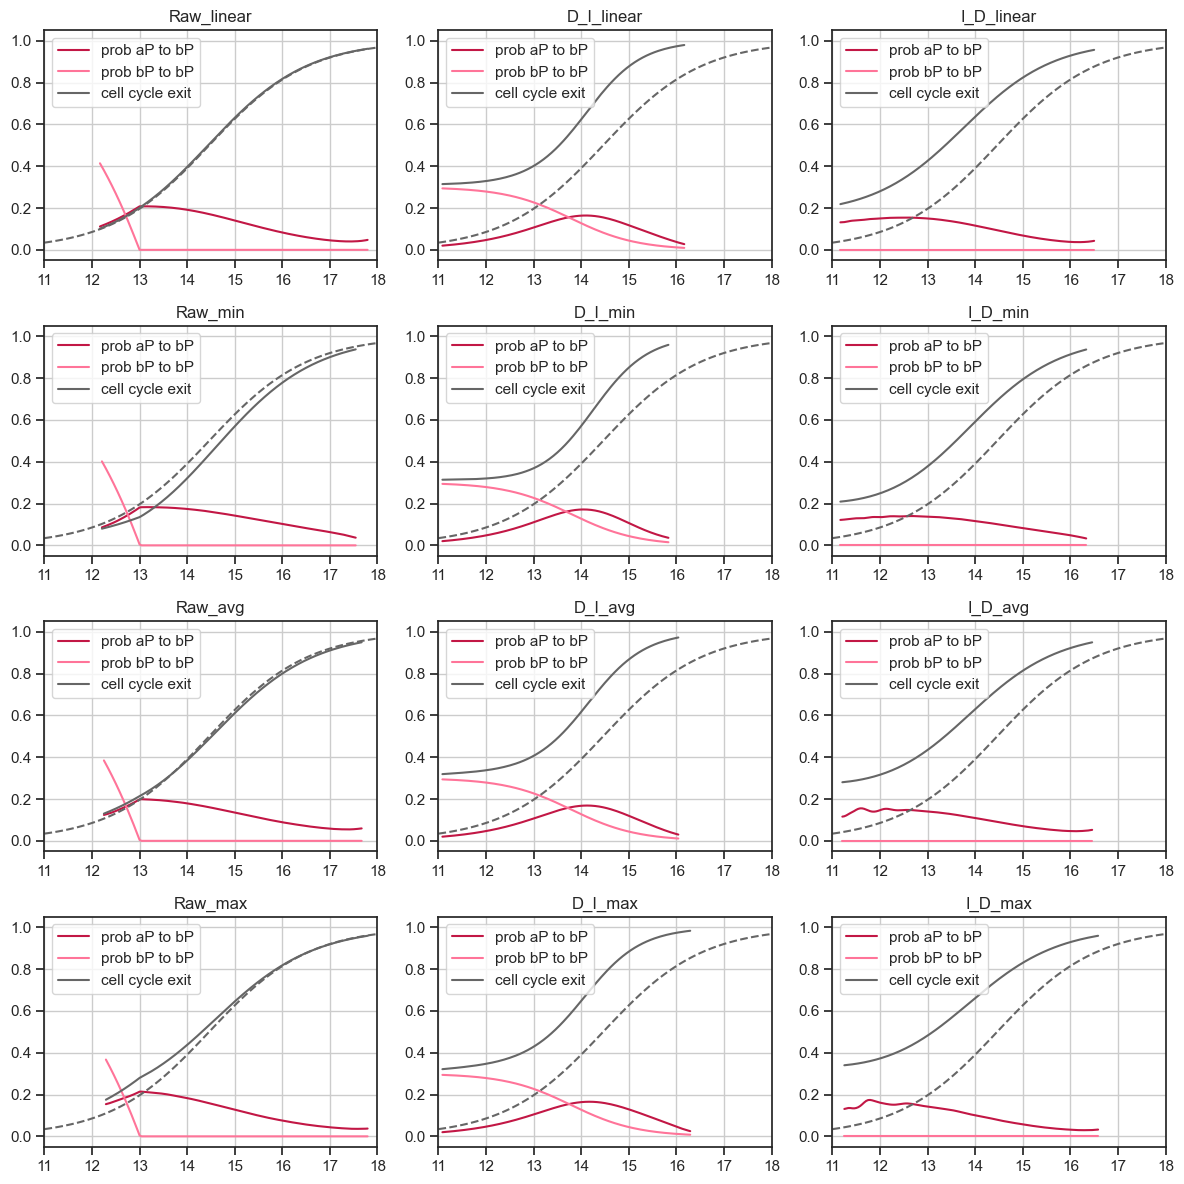

In [29]:
k = len(sims)

default_pE = lambda x: 1/(1 + np.exp(-0.9620962961790901*(x-3.4620613854762183)))
x_0 = np.linspace(0,7, 100)

rows = 4
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))



for i in range(rows):
    for j in range(cols):
        ax = axes[i,j]

        s = sim_names_np[i,j]

        x = days_vc

        y_pE = tables_dict[s]['probs'][5]
        y_pA_to_B = tables_dict[s]['probs'][1]
        y_pB_to_B = tables_dict[s]['probs'][3]


        current_start = start_points_dict[s]
        current_end = end_points_dict[s]

        y_pE[x<current_start] = None
        y_pE[x>current_end] = None

        y_pA_to_B[x<current_start] = None
        y_pA_to_B[x>current_end] = None

        y_pB_to_B[x<current_start] = None
        y_pB_to_B[x>current_end] = None


        ax.plot(x, y_pA_to_B, color = neuro_colors_dict['basal P'], label = 'prob aP to bP')
        ax.plot(x, y_pB_to_B, color = neuro_colors[5], label = 'prob bP to bP')
        ax.plot(x, y_pE, color = neuro_colors[4], label = 'cell cycle exit')
        
        ax.plot(x_0+11, default_pE(x_0), color = neuro_colors[4], linestyle='--')

        ax.set_title(f'{s}')

        ax.set_xlim([11,18])
        ax.set_ylim([-0.05,1.05])

        ax.legend()
        ax.grid()

# # hide any unused subplots if k < rows*cols
# for j in range(k, cols):
#     fig.delaxes(axes[j])

plt.tight_layout()

plt.show()

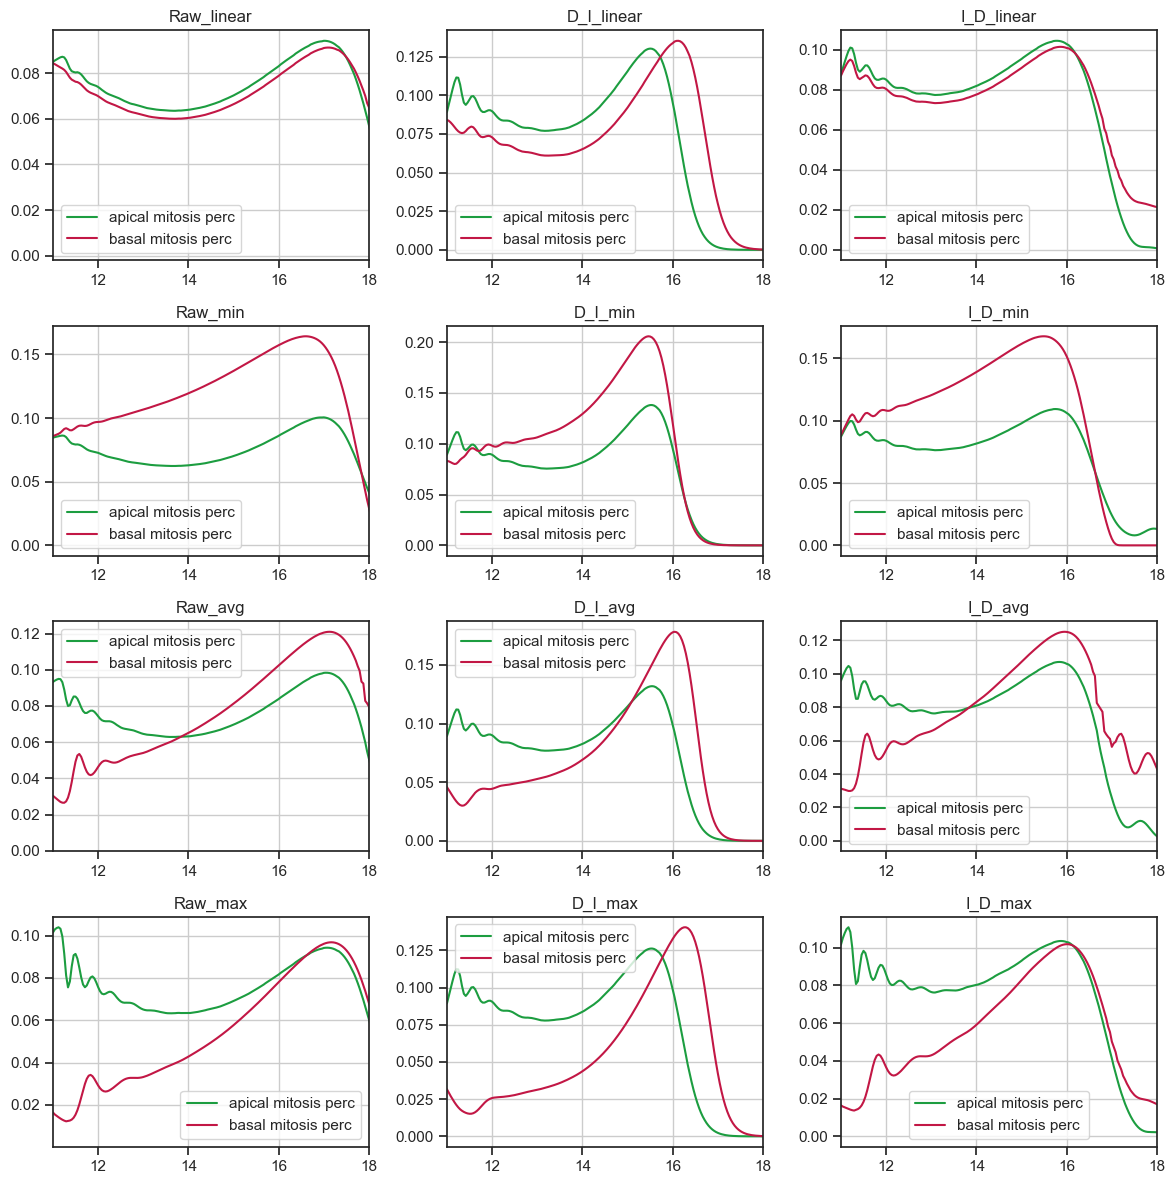

In [30]:
k = len(sims)

rows = 4
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))



for i in range(rows):
    for j in range(cols):
        ax = axes[i,j]

        s = sim_names_np[i,j]

        x = days_vc

        progenitor_n = tables_dict[s]['n_cells'][:2]

        prog_a = progenitor_n[0]
        prog_b = progenitor_n[1]

        mitosis_n = tables_dict[s]['n_mitos']

        mito_a = mitosis_n[0]
        mito_b = mitosis_n[1]

        current_start = start_points_dict[s]
        current_end = end_points_dict[s]

        y_a[x<current_start] = None
        y_a[x>current_end] = None

        y_b[x<current_start] = None
        y_b[x>current_end] = None

        ax.plot(x, mito_a/prog_a, color = neuro_colors_dict['apical P'], label = 'apical mitosis perc')
        ax.plot(x, mito_b/prog_b, color = neuro_colors_dict['basal P'], label = 'basal mitosis perc')
        ax.set_title(f'{s}')

        ax.set_xlim([11,18])

        ax.legend()
        ax.grid()

# hide any unused subplots if k < rows*cols
# for j in range(k, cols):
#     fig.delaxes(axes[j])

plt.tight_layout()

plt.show()

# layers

In [31]:
layers_n_df = pd.DataFrame()

layers_n_df = metrics_df[[col for col in metrics_df.columns if col.endswith('_n')]]
layers_n_df.columns = layers_n_df.columns.str.slice(stop=-2)

layers_n_df = layers_n_df.set_index(metrics_df['source'])

print(layers_n_df)

                   l6         l5         l4         l23
source                                                 
Raw_linear   9.555785  28.897397  34.765555  146.942029
Raw_min     11.628908  35.798739  43.136481  169.960877
Raw_avg      7.915795  25.101679  30.982012  130.630215
Raw_max      5.583258  18.240017  23.049171  104.234801
D_I_linear   6.311890   8.096867   5.566399    8.708176
D_I_min      6.781589   9.230014   6.453630    8.773891
D_I_avg      6.086098   7.946652   5.634772    8.695394
D_I_max      5.704160   7.139009   5.015797    8.767828
I_D_linear   7.874192  11.213996   7.173196   11.244984
I_D_min      8.578852  12.446412   7.932797   11.694570
I_D_avg      7.264027  10.838795   7.128273   11.159926
I_D_max      6.266443   9.654856   6.554531   10.886168


In [32]:
layers_p_df = pd.DataFrame()

layers_p_df = metrics_df[[col for col in metrics_df.columns if col.endswith('_p')]]
layers_p_df.columns = layers_p_df.columns.str.slice(stop=-2)

layers_p_df = layers_p_df.set_index(metrics_df['source'])

layers_p_df

,l6,l5,l4,l23
source,,,,
Raw_linear,0.043404,0.131256,0.157910,0.667431
Raw_min,0.044636,0.137410,0.165575,0.652378
Raw_avg,0.040671,0.128971,0.159184,0.671173
Raw_max,0.036949,0.120709,0.152535,0.689807
D_I_linear,0.220054,0.282285,0.194064,0.303597
D_I_min,0.217086,0.295463,0.206588,0.280862
D_I_avg,0.214579,0.280178,0.198667,0.306576
D_I_max,0.214226,0.268114,0.188374,0.329286
I_D_linear,0.209943,0.298989,0.191253,0.299815


### layer absolute numbers

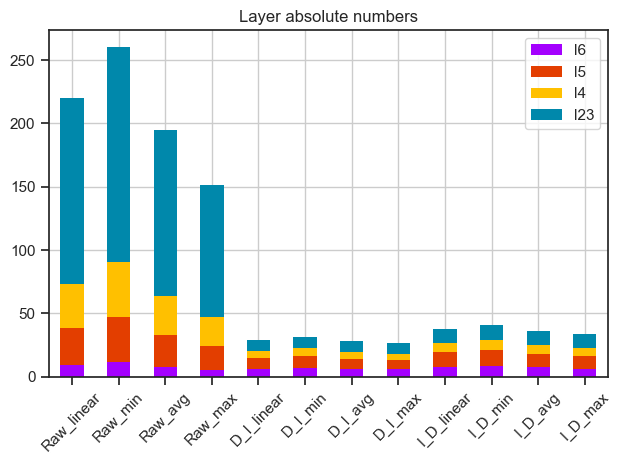

In [33]:
fig, ax = plt.subplots()

layers_n_df.plot(kind='bar', stacked=True, color = colors, edgecolor='none', linewidth=0, ax=ax)
ax.set_xticklabels(layers_n_df.index, rotation = 0)
ax.grid()
ax.set_axisbelow(True)
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=45)
ax.set_title('Layer absolute numbers')

plt.tight_layout()

### layer percentages

In [34]:
layers_density = pd.read_csv(Path.cwd().parent / 'supplementary' /'layers_percent.csv')
# i want to sum starting from l6
layers_perc = layers_density['percent'].values[::-1]

print(layers_density)
print()
print(layers_perc)

layers_perc = np.cumsum(layers_perc)
print(layers_perc)

  layer   percent
0   l23  0.295036
1    l4  0.199940
2    l5  0.288617
3    l6  0.216406

[0.21640608 0.28861736 0.19994028 0.29503627]
[0.21640608 0.50502345 0.70496373 1.        ]


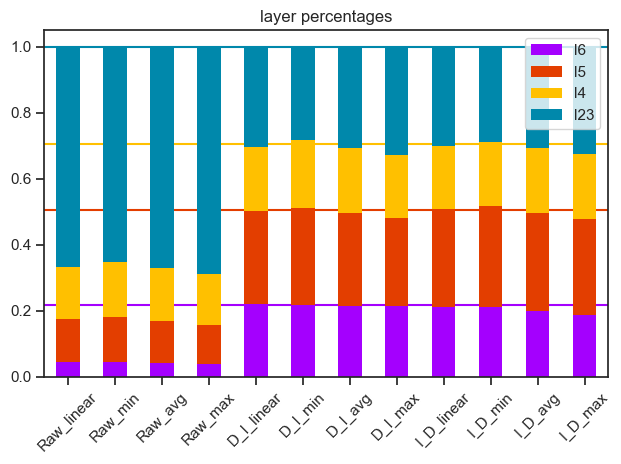

In [35]:
fig, ax = plt.subplots()

layers_p_df.plot(kind='bar', stacked=True, color=colors, ax=ax, edgecolor='none', linewidth=0)
ax.set_xticklabels(layers_p_df.index, rotation = 0)

for i in range(4):
    current_layer =  layers_perc[i]
    ax.hlines(y = current_layer, xmin = -5, xmax = len(layers_p_df), color=colors[i], zorder=0)

ax.set_xlabel('')
ax.tick_params(axis='x', rotation=45)
ax.set_title('layer percentages')
plt.tight_layout()

### direct_indirect layers contribution

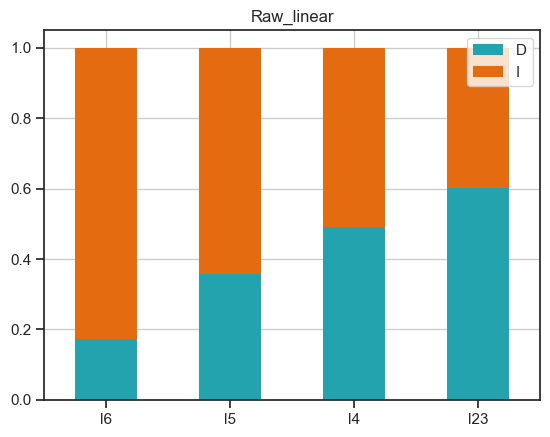

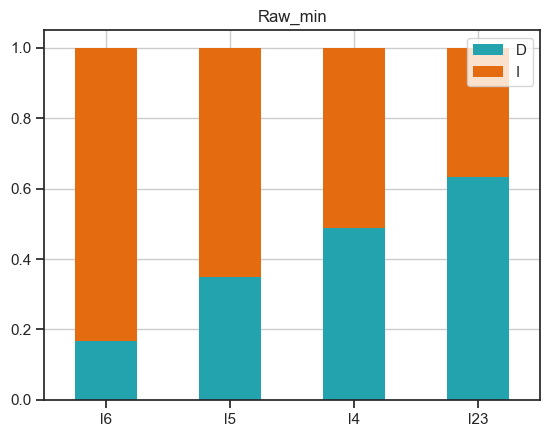

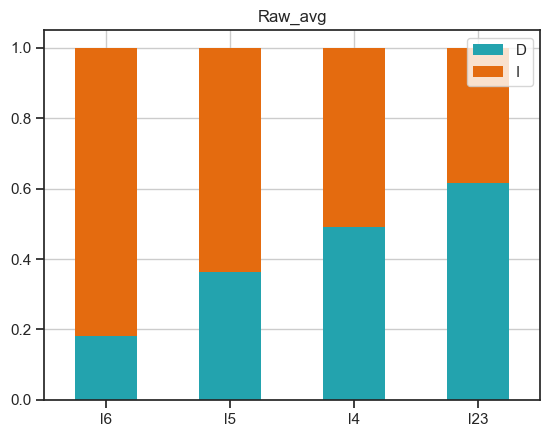

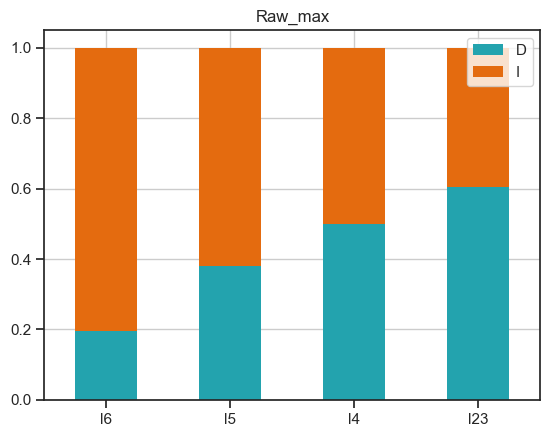

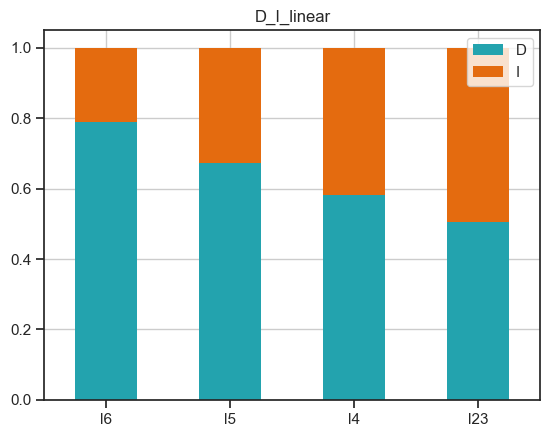

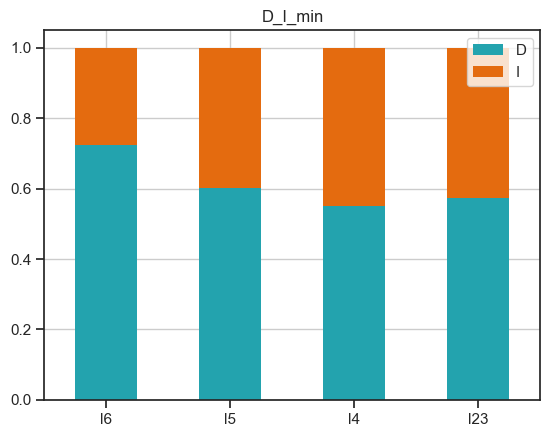

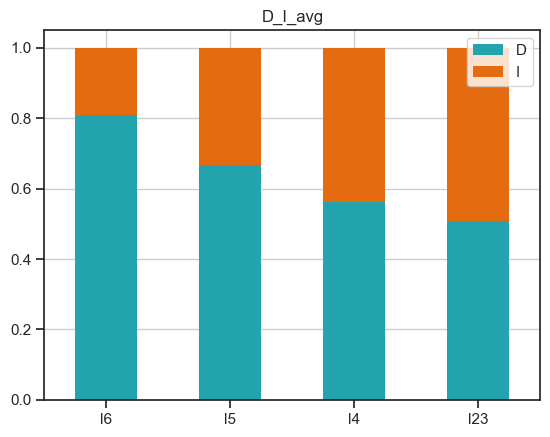

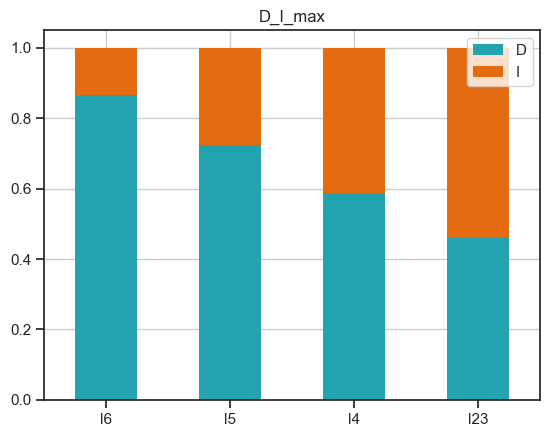

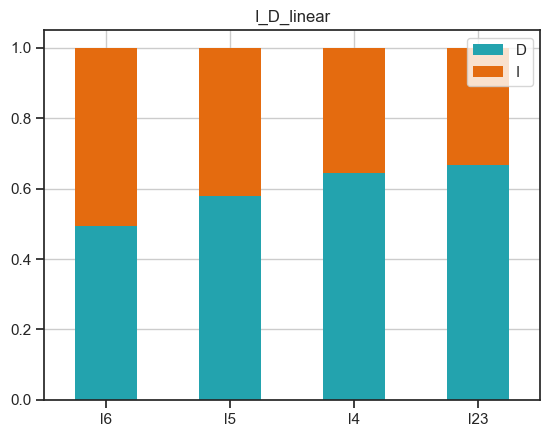

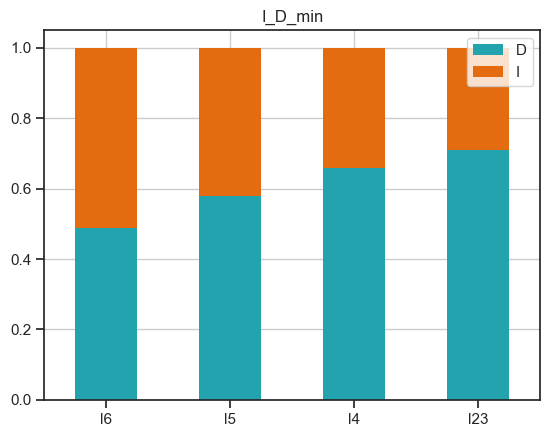

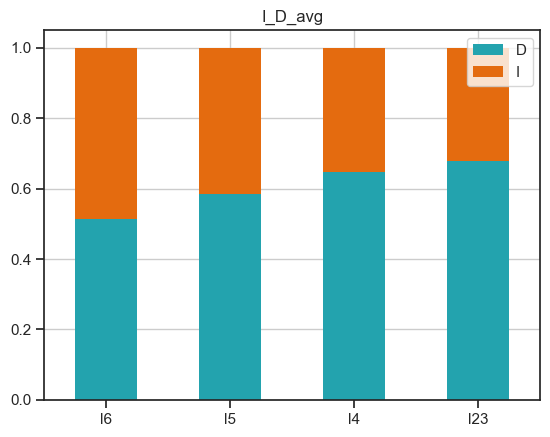

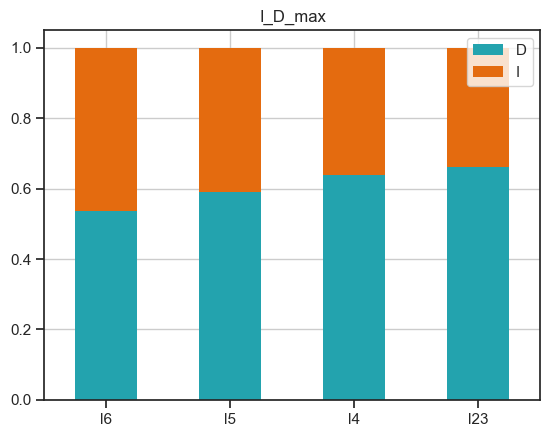

In [36]:
layer_names = list(layer_colors.keys())

for sim_name in sim_names:

    layers_np = tables_dict[sim_name]['layers']

    layers_aggregate = np.sum(layers_np, axis = 2)

    perc_dict = {}

    for i in range(layers_aggregate.shape[1]):
        l = layers_aggregate[:,i]
        
        perc_dict[layer_names[i]] = float(l[0] / np.sum(l))

    perc_df = pd.DataFrame.from_dict(perc_dict, orient='index', columns=['D'])
    perc_df['I'] = 1 - perc_df['D']


    # print(perc_df)
    fig, ax = plt.subplots()

    ax = perc_df.plot(kind='bar', stacked=True, color = neuro_colors[2:4], edgecolor='none', linewidth=0, ax=ax)
    ax.set_xticklabels(perc_df.index, rotation = 0)
    ax.grid()
    ax.set_axisbelow(True)
    ax.set_xlabel('')
    ax.set_title(sim_name)
